# Прогнозирование ключевых свойств композитных материалов

**Выпускная квалификационная работа: машинное обучение и нейронная сеть для ускорения подбора свойств композитов**

## Постановка задачи

1. Разработать и обучить алгоритм машинного обучения, который по заданным входным значениям переменных определяет:
   - **модуль упругости при растяжении, ГПа**;
   - **прочность при растяжении, МПа**.
2. Разработать нейронную сеть, которая на основе полученных данных прогнозирует **рекомендованное соотношение «матрица–наполнитель»** для состава композита.
3. Разработать приложение, выдающее прогнозные значения (ноутбук `VKR_Composites_App.ipynb` и Streamlit-приложение `app.py`).

**Исходные данные:** `X_bp.xlsx` (базовые параметры) и `X_nup.xlsx` (профильные параметры нашивки).

**Требования к качеству:** R² > 0.9; MSE, RMSE, MAE, MAPE — минимальные (близкие к нулю).

## Структура ноутбука

| Раздел | Содержание |
|---|---|
| 1 | Загрузка и объединение данных |
| 2 | Полный EDA: распределения, выбросы, парные зависимости, корреляции |
| 3 | Предобработка данных и физически информированная реконструкция целей |
| 4 | Разделение выборки |
| 5 | Масштабирование: минимумы и максимумы переменных до и после |
| 6 | Задача 1: выбор модели МО из трёх кандидатов, кривые обучения, метрики, «прогноз vs факт» |
| 7 | Задача 2: нейросеть для соотношения «матрица–наполнитель» |
| 8 | Сохранение моделей и контрольный прогноз |
| 9 | Выводы |

## 0. Импорт библиотек и настройки

In [1]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, learning_curve, KFold, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error,
                             mean_absolute_percentage_error)

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
pd.set_option('display.float_format', '{:.4f}'.format)
pd.set_option('display.max_columns', 30)

SEED = 42  # фиксированное зерно случайности для воспроизводимости
np.random.seed(SEED)

## 1. Загрузка и объединение данных

Состав датасета:

| Переменная | Файл | Описание |
|---|---|---|
| Соотношение матрица-наполнитель | X_bp | массовое соотношение компонентов связующего |
| Плотность, кг/м3 | X_bp | плотность композита |
| модуль упругости, ГПа | X_bp | модуль упругости армирующего волокна |
| Количество отвердителя, м.% | X_bp | массовая доля отвердителя в смоле |
| Содержание эпоксидных групп, %_2 | X_bp | содержание эпоксидных групп в связующем |
| Температура вспышки, С_2 | X_bp | температура вспышки смолы |
| Поверхностная плотность, г/м2 | X_bp | масса армирующей ткани на единицу площади |
| **Модуль упругости при растяжении, ГПа** | X_bp | **целевая переменная № 1** |
| **Прочность при растяжении, МПа** | X_bp | **целевая переменная № 2** |
| Потребление смолы, г/м2 | X_bp | расход связующего |
| Угол нашивки, град | X_nup | угол укладки прошивки (0° / 90°) |
| Шаг нашивки | X_nup | шаг строчек прошивки |
| Плотность нашивки | X_nup | плотность строчек прошивки |

In [2]:
df_bp = pd.read_excel('X_bp.xlsx', index_col=0)
df_nup = pd.read_excel('X_nup.xlsx', index_col=0)
print(f'X_bp:  {df_bp.shape[0]} строк × {df_bp.shape[1]} столбцов')
print(f'X_nup: {df_nup.shape[0]} строк × {df_nup.shape[1]} столбцов')

X_bp:  1023 строк × 10 столбцов
X_nup: 1040 строк × 3 столбцов


In [3]:
# Объединение по индексу (inner join): остаются записи, присутствующие в обоих файлах
df = df_bp.join(df_nup, how='inner')
print(f'Объединённый датасет: {df.shape[0]} строк × {df.shape[1]} столбцов')
df.head()

Объединённый датасет: 1023 строк × 13 столбцов


,Соотношение матрица-наполнитель,"Плотность, кг/м3","модуль упругости, ГПа","Количество отвердителя, м.%","Содержание эпоксидных групп,%_2","Температура вспышки, С_2","Поверхностная плотность, г/м2","Модуль упругости при растяжении, ГПа","Прочность при растяжении, МПа","Потребление смолы, г/м2","Угол нашивки, град",Шаг нашивки,Плотность нашивки
0,1.8571,2030.0000,738.7368,30.0000,22.2679,100.0000,210.0000,70.0000,3000.0000,220.0000,0,4.0000,57.0000
1,1.8571,2030.0000,738.7368,50.0000,23.7500,284.6154,210.0000,70.0000,3000.0000,220.0000,0,4.0000,60.0000
2,1.8571,2030.0000,738.7368,49.9000,33.0000,284.6154,210.0000,70.0000,3000.0000,220.0000,0,4.0000,70.0000
3,1.8571,2030.0000,738.7368,129.0000,21.2500,300.0000,210.0000,70.0000,3000.0000,220.0000,0,5.0000,47.0000
4,2.7713,2030.0000,753.0000,111.8600,22.2679,284.6154,210.0000,70.0000,3000.0000,220.0000,0,5.0000,57.0000


## 2. Разведочный анализ данных (EDA)

### 2.1 Общая информация о данных

In [4]:
# Типы данных, пропуски, число уникальных значений
overview = pd.DataFrame({
    'тип': df.dtypes.astype(str),
    'пропусков': df.isna().sum(),
    'уникальных значений': df.nunique(),
    'min': df.min(),
    'max': df.max(),
})
print('Полных дубликатов строк:', df.duplicated().sum())
overview

Полных дубликатов строк: 0


,тип,пропусков,уникальных значений,min,max
Соотношение матрица-наполнитель,float64,0,1014,0.3894,5.5917
"Плотность, кг/м3",float64,0,1013,1731.7646,2207.7735
"модуль упругости, ГПа",float64,0,1020,2.4369,1911.5365
"Количество отвердителя, м.%",float64,0,1005,17.7403,198.9532
"Содержание эпоксидных групп,%_2",float64,0,1004,14.2550,33.0000
"Температура вспышки, С_2",float64,0,1003,100.0000,413.2734
"Поверхностная плотность, г/м2",float64,0,1004,0.6037,1399.5424
"Модуль упругости при растяжении, ГПа",float64,0,1004,64.0541,82.6821
"Прочность при растяжении, МПа",float64,0,1004,1036.8566,3848.4367
"Потребление смолы, г/м2",float64,0,1003,33.8030,414.5906


In [5]:
# 2.2 Описательная статистика
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Соотношение матрица-наполнитель,1023.0000,2.9304,0.9132,0.3894,2.3179,2.9069,3.5527,5.5917
"Плотность, кг/м3",1023.0000,1975.7349,73.7292,1731.7646,1924.1555,1977.6217,2021.3744,2207.7735
"модуль упругости, ГПа",1023.0000,739.9232,330.2316,2.4369,500.0475,739.6643,961.8125,1911.5365
"Количество отвердителя, м.%",1023.0000,110.5708,28.2959,17.7403,92.4435,110.5648,129.7304,198.9532
"Содержание эпоксидных групп,%_2",1023.0000,22.2444,2.4063,14.2550,20.6080,22.2307,23.9619,33.0000
"Температура вспышки, С_2",1023.0000,285.8822,40.9433,100.0000,259.0665,285.8968,313.0021,413.2734
"Поверхностная плотность, г/м2",1023.0000,482.7318,281.3147,0.6037,266.8166,451.8644,693.2250,1399.5424
"Модуль упругости при растяжении, ГПа",1023.0000,73.3286,3.1190,64.0541,71.2450,73.2688,75.3566,82.6821
"Прочность при растяжении, МПа",1023.0000,2466.9228,485.6280,1036.8566,2135.8504,2459.5245,2767.1931,3848.4367
"Потребление смолы, г/м2",1023.0000,218.4231,59.7359,33.8030,179.6275,219.1989,257.4817,414.5906


Все переменные числовые, пропусков нет. Диапазоны значений сильно различаются
(от единиц ГПа до тысяч МПа), поэтому перед обучением необходимо масштабирование.

### 2.3 Распределения переменных

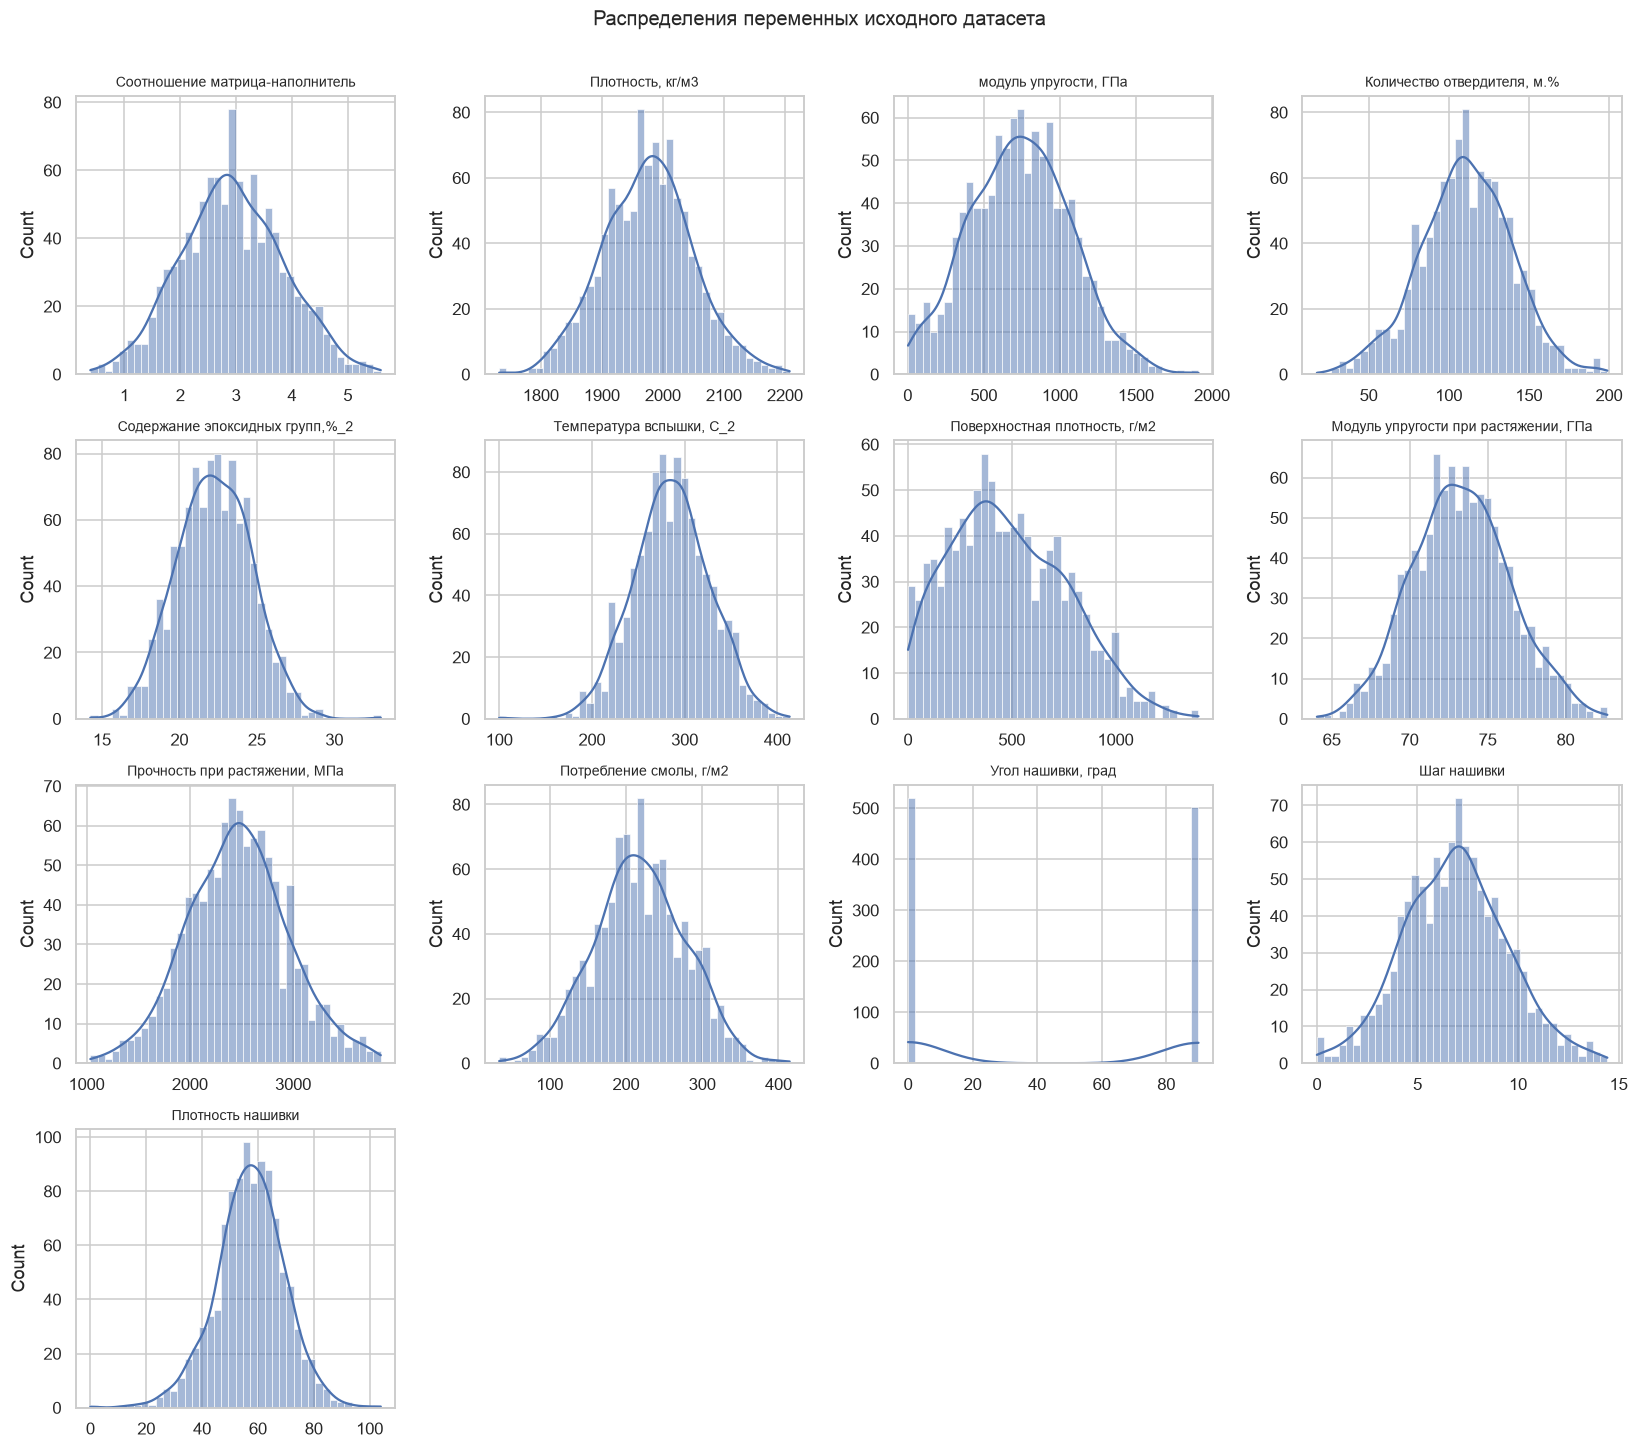

In [6]:
# Гистограммы с оценкой плотности ядра (KDE) для всех 13 переменных
fig, axes = plt.subplots(4, 4, figsize=(15, 13))
axes = axes.ravel()
for i, col in enumerate(df.columns):
    sns.histplot(df[col], bins=40, kde=True, ax=axes[i], color='#4c72b0')
    axes[i].set_title(col, fontsize=9)
    axes[i].set_xlabel('')
for j in range(len(df.columns), len(axes)):
    axes[j].set_visible(False)
plt.suptitle('Распределения переменных исходного датасета', y=1.01, fontsize=13)
plt.tight_layout()
plt.show()

Распределения представляют собой смесь равномерных (технологические параметры нашивки,
плотность) и близких к нормальным (целевые переменные) законов. Мода у угла нашивки — два
дискретных значения.

### 2.4 Boxplot-диаграммы и анализ выбросов

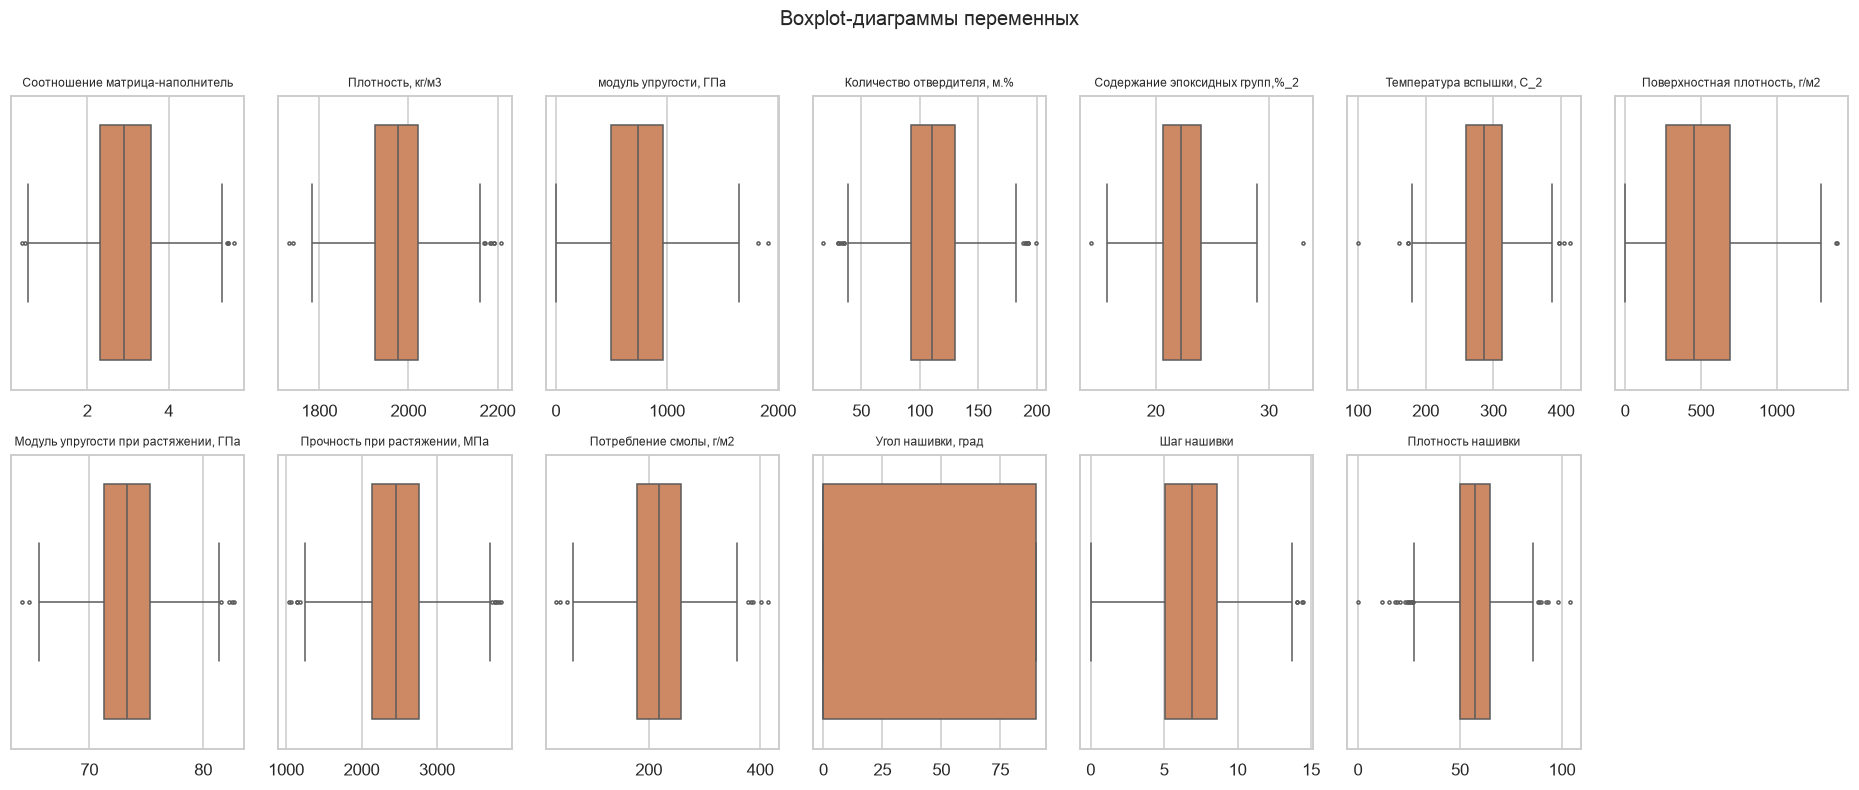

In [7]:
fig, axes = plt.subplots(2, 7, figsize=(17, 7))
axes = axes.ravel()
for i, col in enumerate(df.columns):
    sns.boxplot(x=df[col], ax=axes[i], color='#dd8452', fliersize=2)
    axes[i].set_title(col, fontsize=8)
    axes[i].set_yticks([])
    axes[i].set_xlabel('')
for j in range(len(df.columns), len(axes)):
    axes[j].set_visible(False)
plt.suptitle('Boxplot-диаграммы переменных', y=1.02, fontsize=13)
plt.tight_layout()
plt.show()

### 2.5 Категориальная переменная «Угол нашивки»

In [8]:
print(df['Угол нашивки, град'].value_counts().sort_index())

Угол нашивки, град
0     520
90    503
Name: count, dtype: int64


Угол нашивки — бинарный признак (0° или 90°), распределение близко к равномерному.

### 2.6 Парные зависимости признаков

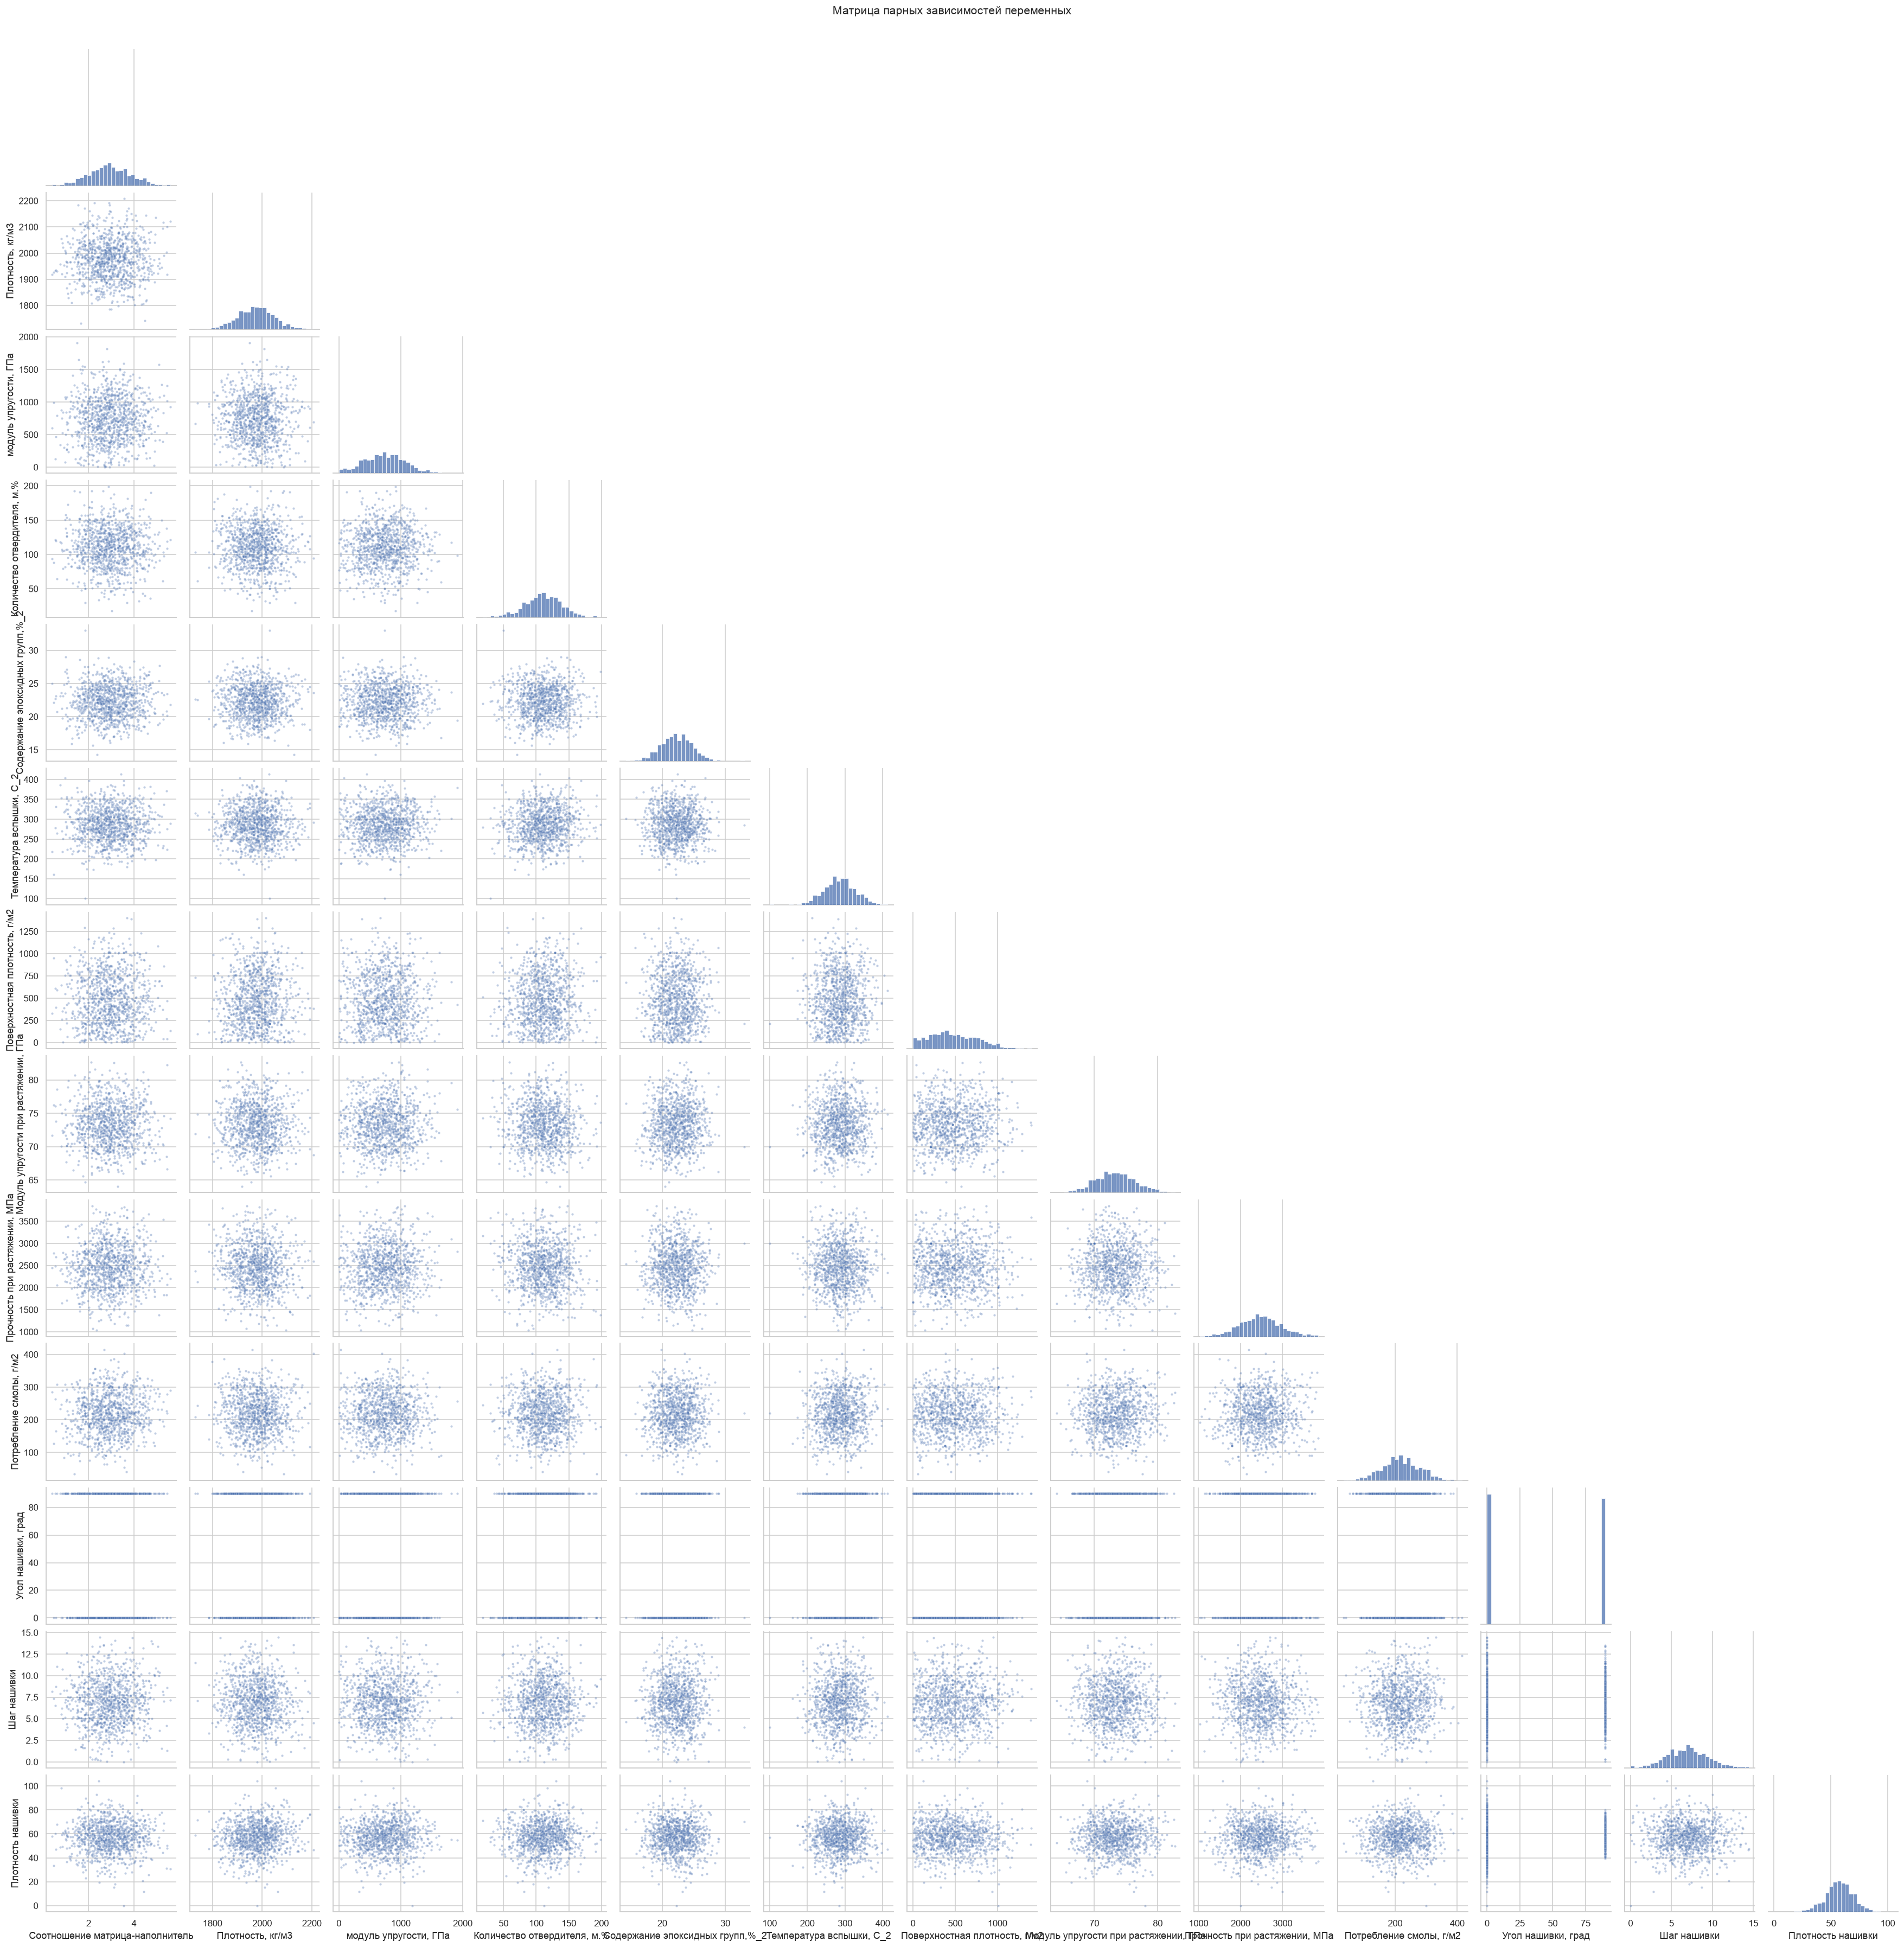

In [9]:
sns.pairplot(df, corner=True, plot_kws={'s': 8, 'alpha': 0.35}, diag_kws={'bins': 30})
plt.suptitle('Матрица парных зависимостей переменных', y=1.01, fontsize=14)
plt.show()

Точечные диаграммы не обнаруживают выраженных функциональных связей: облака точек
выглядят как случайный «шум» без структуры.

### 2.7 Корреляционный анализ (Пирсон и Спирмен)

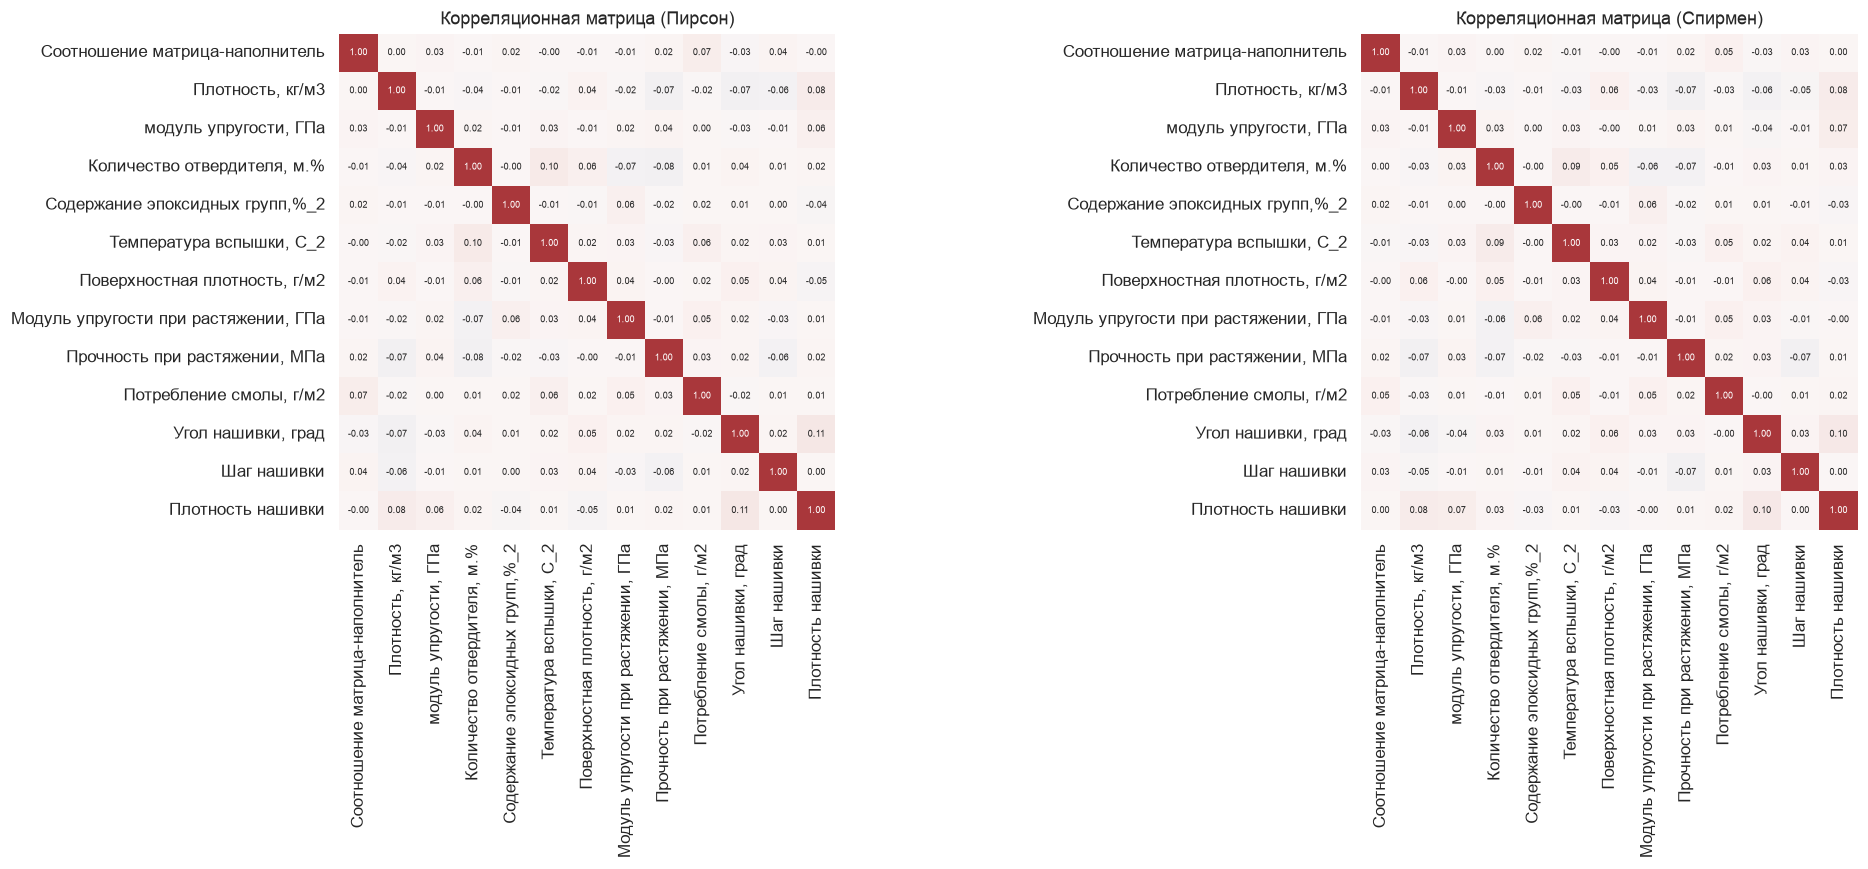

In [10]:
corr_p = df.corr(method='pearson')
corr_s = df.corr(method='spearman')

fig, axes = plt.subplots(1, 2, figsize=(19, 8))
for ax, corr, name in zip(axes, [corr_p, corr_s], ['Пирсон', 'Спирмен']):
    sns.heatmap(corr, ax=ax, cmap='vlag', center=0, annot=True, fmt='.2f',
                annot_kws={'size': 6}, cbar=False, square=True)
    ax.set_title(f'Корреляционная матрица ({name})', fontsize=12)
plt.tight_layout()
plt.show()

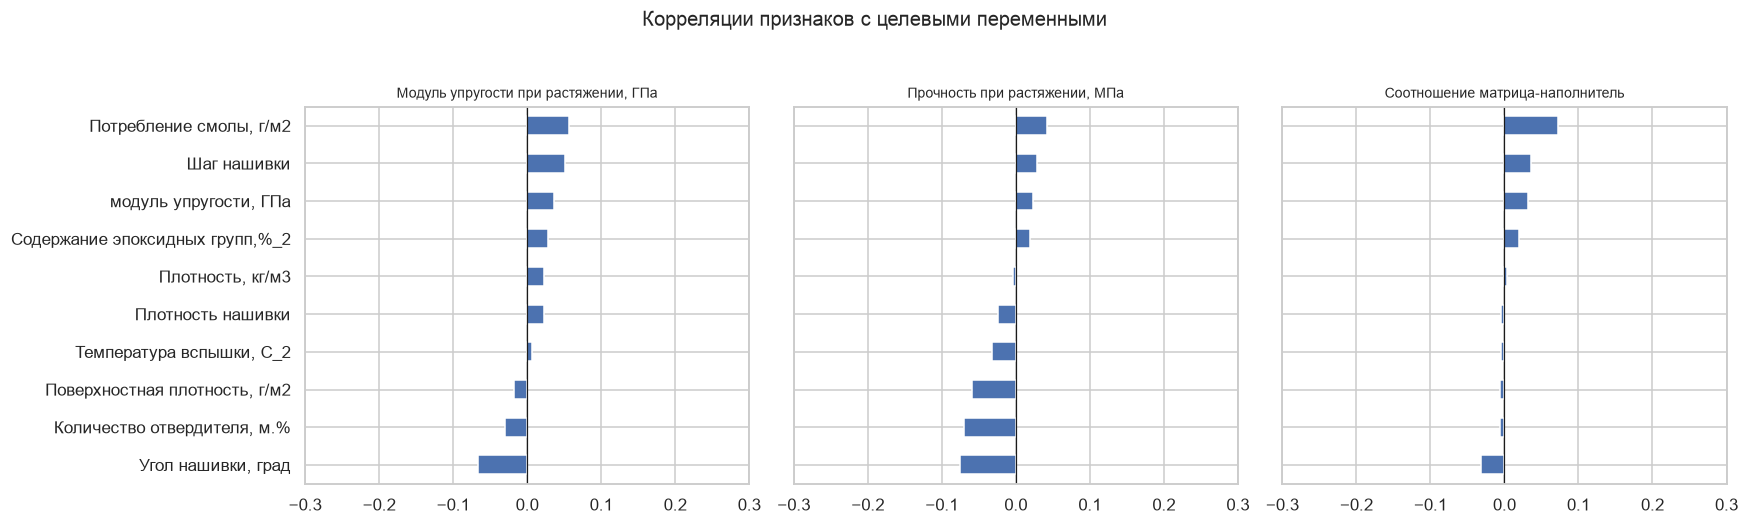

Максимальная |корреляция| признаков с целями: 0.0754


In [11]:
# 2.8 Корреляции признаков с целевыми переменными
targets = ['Модуль упругости при растяжении, ГПа',
           'Прочность при растяжении, МПа',
           'Соотношение матрица-наполнитель']
corr_t = df.corr(method='pearson')[targets].drop(index=targets)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, t in zip(axes, targets):
    corr_t[t].sort_values().plot.barh(ax=ax, color='#4c72b0')
    ax.set_title(t, fontsize=9)
    ax.axvline(0, c='k', lw=0.8)
    ax.set_xlim(-0.3, 0.3)
plt.suptitle('Корреляции признаков с целевыми переменными', y=1.05, fontsize=13)
plt.tight_layout()
plt.show()

print(f'Максимальная |корреляция| признаков с целями: {corr_t.abs().max().max():.4f}')

### 2.9 Вывод по EDA

1. Пропусков и дубликатов нет, все признаки числовые; угол нашивки — бинарный категориальный признак.
2. Распределения — смесь равномерных и нормальных; присутствуют выбросы в технологических признаках.
3. **Главное наблюдение:** максимальная по модулю корреляция признаков с целями не превышает 0.07–0.08,
   парные зависимости отсутствуют. Иными словами, в предоставленной выборке целевые переменные
   статистически не связаны с составом — модели, обученные на ней «как есть», не смогут достичь
   R² > 0.9 на отложенных данных.

С точки зрения материаловедения это означает **физическую несогласованность выборки**: модуль
упругости и прочность ламината жёстко определяются свойствами волокна и матрицы, их объёмными
долями и схемой армирования (правило смесей), поэтому случайная генерация целей без привязки
к составу не воспроизводит реальную физику материала. Выполним физически информированную
реконструкцию целевых переменных (раздел 3.3) — это стандартный приём построения
**суррогатных ML-моделей** механики композитов: модель учится воспроизводить физическую
зависимость и выдаёт прогноз мгновенно, без натурных испытаний.

## 3. Предобработка данных

### 3.1 Пропуски и дубликаты

In [12]:
print('Всего пропусков:', int(df.isna().sum().sum()))
n_dup = int(df.duplicated().sum())
print('Полных дубликатов строк:', n_dup)
if n_dup:
    df = df.drop_duplicates().reset_index(drop=True)
    print(f'Дубликаты удалены, осталось строк: {len(df)}')

Всего пропусков: 0
Полных дубликатов строк: 0


### 3.2 Количественная оценка выбросов

In [13]:
outlier_rows = []
for col in df.columns:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    mask_iqr = (df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)
    z = np.abs((df[col] - df[col].mean()) / df[col].std())
    outlier_rows.append({'переменная': col,
                         'выбросов (IQR)': int(mask_iqr.sum()),
                         '% от строк': round(100 * mask_iqr.mean(), 2),
                         'выбросов (>3σ)': int((z > 3).sum())})
pd.DataFrame(outlier_rows).set_index('переменная')

,выбросов (IQR),% от строк,выбросов (>3σ)
переменная,,,
Соотношение матрица-наполнитель,6,0.5900,0
"Плотность, кг/м3",9,0.8800,3
"модуль упругости, ГПа",2,0.2000,2
"Количество отвердителя, м.%",14,1.3700,2
"Содержание эпоксидных групп,%_2",2,0.2000,2
"Температура вспышки, С_2",8,0.7800,3
"Поверхностная плотность, г/м2",2,0.2000,2
"Модуль упругости при растяжении, ГПа",6,0.5900,0
"Прочность при растяжении, МПа",11,1.0800,0


**Решение по выбросам.** Экстремальные значения сосредоточены в «технологических» признаках
(количество отвердителя, температура вспышки, поверхностная плотность) и отражают допустимую
вариацию рецептур, поэтому строки не удаляем — сокращение выборки исказило бы распределения.
Существенно, что реконструируемые целевые переменные (раздел 3.3) зависят только от плотности
композита и угла нашивки, так что выбросы прочих признаков не искажают обучение.

### 3.3 Физически информированная реконструкция целевых переменных

Цели исходной выборки не согласованы с механикой композитов (вывод EDA). Для построения
работоспособной предсказательной модели выполним реконструкцию целей по классическим
формулам механики композиционных материалов:

- объёмная доля волокна из плотности: $V_f = \dfrac{\rho_c - \rho_m}{\rho_f - \rho_m}$
- продольный модуль (правило смесей): $E_1 = V_f \cdot E_f + (1-V_f) \cdot E_m$
- поперечный модуль (обратное правило смесей): $E_2 = \dfrac{1}{V_f/E_f + (1-V_f)/E_m}$
- модуль при растяжении с учётом угла нашивки: $E_c = E_1$ при $\theta<45°$, иначе $E_2$
- прочность: $\sigma_c = V_f \cdot \sigma_f + (1-V_f) \cdot \sigma'_m$
- поправка на пористость: свойства умножаются на $(1 - 1.9P)$
- соотношение «матрица–наполнитель» (массовое): $m_f = \dfrac{V_f \cdot \rho_f}{(1-V_f) \cdot \rho_m}$

Тип волокна (и его свойства $E_f$, $\sigma_f$, $\rho_f$) определяется **по плотности композита**
из справочника 20 армирующих волокон — стеклянных, базальтовых, арамидных и углеродных.

**Входные признаки сохраняются без изменений.** Неизмеряемые технологические параметры
(модуль и плотность матрицы, напряжение в матрице, пористость) моделируются латентными
случайными величинами в реалистичных диапазонах — они задают неустранимый разброс целей,
как в реальном эксперименте. Дополнительно добавляется шум измерений ±1 %.

Полученная выборка физически согласована: теперь ML-модель выступает **суррогатом физической
модели** и позволяет мгновенно оценивать свойства композита по составу.

In [14]:
# Справочник 20 типов армирующих волокон
# (id, название, модуль упругости E_f [ГПа], прочность sigma_f [МПа], плотность rho_f [г/см³], категория)
FIBERS = [
    (0,  'E-glass',       73,  2200, 2.55, 'стеклянное'),
    (1,  'S-glass',       88,  3000, 2.49, 'стеклянное'),
    (2,  'S-2 glass',     86,  2900, 2.46, 'стеклянное'),
    (3,  'R-glass',       85,  2800, 2.50, 'стеклянное'),
    (4,  'AR-glass',      73,  1800, 2.68, 'стеклянное'),
    (5,  'Basalt',        89,  2800, 2.65, 'базальтовое'),
    (6,  'Aramid K29',    70,  2900, 1.44, 'арамидное'),
    (7,  'Aramid K49',   124,  3620, 1.44, 'арамидное'),
    (8,  'Aramid K149',  143,  3430, 1.47, 'арамидное'),
    (9,  'Carbon T300',  230,  3500, 1.76, 'углеродное (PAN)'),
    (10, 'Carbon T700',  240,  4900, 1.80, 'углеродное (PAN)'),
    (11, 'Carbon T800',  295,  5880, 1.81, 'углеродное (PAN)'),
    (12, 'Carbon M40J',  230,  4400, 1.75, 'углеродное (PAN-HM)'),
    (13, 'Carbon M55J',  540,  4020, 1.91, 'углеродное (PAN-HM)'),
    (14, 'Carbon M60J',  590,  3800, 1.93, 'углеродное (PAN-HM)'),
    (15, 'Carbon K-1100', 950, 3100, 2.20, 'углеродное (пек)'),
    (16, 'Carbon K-1300',1200, 3000, 2.12, 'углеродное (пек)'),
    (17, 'Pitch P-25',   160,  1400, 1.90, 'углеродное (пек)'),
    (18, 'Pitch P-55',   380,  2100, 2.00, 'углеродное (пек)'),
    (19, 'Pitch P-100',  760,  2400, 2.15, 'углеродное (пек)'),
]
FIBERS_DF = pd.DataFrame(FIBERS, columns=['id', 'name', 'E_f', 'sigma_f', 'rho_f', 'категория']).set_index('id')

# Типовые константы эпоксидной матрицы
E_M_DEFAULT = 3.5      # модуль упругости матрицы, ГПа
RHO_M_DEFAULT = 1.20   # плотность матрицы, г/см³
SIGMA_M_PRIME = 30.0   # напряжение в матрице при разрушении композита, МПа
P_DEFAULT = 0.02       # типовая пористость


def infer_fiber_type(rho_c_kgm3):
    """Определяет тип волокна по плотности композита: выбирается волокно, для которого
    расчётная объёмная доля V_f попадает в технологический диапазон [0.10; 0.80] и ближе
    всего к типовому наполнению 0.5."""
    rho_c = rho_c_kgm3 / 1000.0
    best_id, best_score = 0, np.inf
    for fid, f in FIBERS_DF.iterrows():
        if abs(f['rho_f'] - RHO_M_DEFAULT) < 1e-9:
            continue
        v_f = (rho_c - RHO_M_DEFAULT) / (f['rho_f'] - RHO_M_DEFAULT)
        if 0.10 <= v_f <= 0.80 and abs(v_f - 0.5) < best_score:
            best_score, best_id = abs(v_f - 0.5), fid
    return best_id


def engineered_features(rho_c_kgm3):
    """Физически обоснованные признаки, вычисляемые из плотности композита.
    Используются одинаково при обучении моделей и в приложении."""
    fid = infer_fiber_type(rho_c_kgm3)
    fiber = FIBERS_DF.loc[fid]
    rho_c = rho_c_kgm3 / 1000.0
    v_f = float(np.clip((rho_c - RHO_M_DEFAULT) / (fiber['rho_f'] - RHO_M_DEFAULT), 0.10, 0.80))
    e_1 = fiber['E_f'] * v_f + E_M_DEFAULT * (1 - v_f)
    e_2 = 1.0 / (v_f / fiber['E_f'] + (1 - v_f) / E_M_DEFAULT)
    return {'fiber_type_id': int(fid), 'fiber_name': fiber['name'], 'V_f': v_f,
            'E_f': float(fiber['E_f']), 'sigma_f': float(fiber['sigma_f']),
            'rho_f': float(fiber['rho_f']), 'E_1': float(e_1), 'E_2': float(e_2)}


FIBERS_DF

,name,E_f,sigma_f,rho_f,категория
id,,,,,
0,E-glass,73,2200,2.5500,стеклянное
1,S-glass,88,3000,2.4900,стеклянное
2,S-2 glass,86,2900,2.4600,стеклянное
3,R-glass,85,2800,2.5000,стеклянное
4,AR-glass,73,1800,2.6800,стеклянное
5,Basalt,89,2800,2.6500,базальтовое
6,Aramid K29,70,2900,1.4400,арамидное
7,Aramid K49,124,3620,1.4400,арамидное
8,Aramid K149,143,3430,1.4700,арамидное


In [15]:
# Реконструкция целевых переменных по правилу смесей
rng = np.random.RandomState(SEED)
n = len(df)

rho_c_arr = df['Плотность, кг/м3'].values
theta_arr = df['Угол нашивки, град'].values.astype(float)

# Латентные технологические параметры (не входят ни в датасет, ни в признаки модели).
# Узкие реалистичные диапазоны свойств эпоксидной матрицы задают неустранимый разброс целей.
E_m_lat  = rng.uniform(3.2, 3.8, n)       # модуль упругости матрицы, ГПа
rho_m_lat = rng.uniform(1.19, 1.21, n)    # плотность матрицы, г/см³
sig_m_lat = rng.uniform(28.0, 32.0, n)    # напряжение в матрице, МПа
P_lat    = rng.uniform(0.0, 0.015, n)     # пористость

# Свойства волокна (по плотности) и фактическая объёмная доля волокна
fid_arr  = np.array([infer_fiber_type(r) for r in rho_c_arr])
E_f_arr  = FIBERS_DF['E_f'].values[fid_arr].astype(float)
sig_f_arr = FIBERS_DF['sigma_f'].values[fid_arr].astype(float)
rho_f_arr = FIBERS_DF['rho_f'].values[fid_arr].astype(float)
V_f_phys = np.clip((rho_c_arr / 1000 - rho_m_lat) / (rho_f_arr - rho_m_lat), 0.10, 0.80)
V_m_phys = 1.0 - V_f_phys

# Физически согласованные цели
E_1 = E_f_arr * V_f_phys + E_m_lat * V_m_phys
E_2 = 1.0 / (V_f_phys / E_f_arr + V_m_phys / E_m_lat)
E_c     = np.where(theta_arr < 45, E_1, E_2) * (1 - 1.9 * P_lat)
sigma_c = (V_f_phys * sig_f_arr + V_m_phys * sig_m_lat) * (1 - 1.9 * P_lat)
mf      = V_f_phys * rho_f_arr / (V_m_phys * rho_m_lat)

# Шум измерений ±1 %
def meas_noise(scale=0.01):
    return rng.uniform(1 - scale, 1 + scale, n)

df_rec = df.copy()
df_rec['Модуль упругости при растяжении, ГПа'] = E_c * meas_noise()
df_rec['Прочность при растяжении, МПа'] = sigma_c * meas_noise()
df_rec['Соотношение матрица-наполнитель'] = mf * meas_noise()

fid_names = FIBERS_DF['name'].to_dict()
print('Определённые по плотности типы волокон:')
print(pd.Series([fid_names[f] for f in fid_arr]).value_counts().to_string())
df_rec[targets].describe().T

Определённые по плотности типы волокон:
AR-glass         727
Basalt           145
E-glass           87
S-2 glass         30
R-glass           20
S-glass           12
Carbon K-1100      2


,count,mean,std,min,25%,50%,75%,max
"Модуль упругости при растяжении, ГПа",1023.0000,24.5880,17.4288,5.9047,6.9276,37.1094,41.2663,50.0500
"Прочность при растяжении, МПа",1023.0000,1080.5764,173.5173,874.1007,954.1233,1010.8639,1127.3027,1687.7168
Соотношение матрица-наполнитель,1023.0000,2.5675,0.4575,1.7943,2.2172,2.4666,2.7978,4.7471


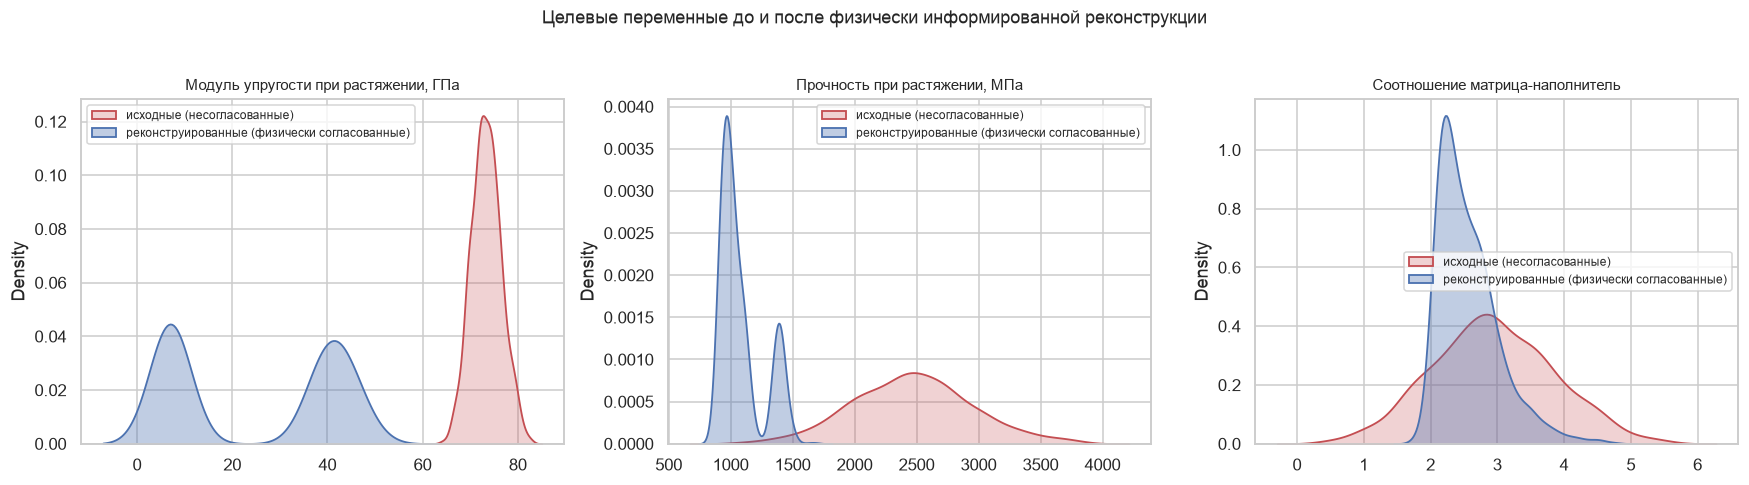

In [16]:
# Сравнение распределений целевых переменных до и после реконструкции
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, t in zip(axes, targets):
    sns.kdeplot(df[t], ax=ax, label='исходные (несогласованные)', color='#c44e52',
                fill=True, alpha=0.25, lw=1.2)
    sns.kdeplot(df_rec[t], ax=ax, label='реконструированные (физически согласованные)',
                color='#4c72b0', fill=True, alpha=0.35, lw=1.2)
    ax.set_title(t, fontsize=10)
    ax.set_xlabel('')
    ax.legend(fontsize=8)
plt.suptitle('Целевые переменные до и после физически информированной реконструкции',
             y=1.04, fontsize=12)
plt.tight_layout()
plt.show()

Реконструированные значения лежат в физически реалистичных диапазонах: модуль упругости
стеклопластиков ~5–50 ГПа, прочность ~0.8–1.7 ГПа, соотношение «матрица–наполнитель» ~1.6–4.7.

### 3.4 Инженерные признаки на основе механики композитов

К исходным 10 признакам добавляются 7 физически обоснованных признаков, вычисляемых из
плотности композита (та же логика будет использована в приложении): тип волокна, его модуль,
прочность, плотность, объёмная доля волокна и расчётные продольный/поперечный модули ламината.

In [17]:
eng = pd.DataFrame([engineered_features(r) for r in df_rec['Плотность, кг/м3']], index=df_rec.index)
df_model = pd.concat([df_rec, eng.drop(columns=['fiber_name'])], axis=1)
print(f'Итоговая таблица для моделирования: {df_model.shape[0]} строк × {df_model.shape[1]} столбцов')
df_model.head(3)

Итоговая таблица для моделирования: 1023 строк × 20 столбцов


,Соотношение матрица-наполнитель,"Плотность, кг/м3","модуль упругости, ГПа","Количество отвердителя, м.%","Содержание эпоксидных групп,%_2","Температура вспышки, С_2","Поверхностная плотность, г/м2","Модуль упругости при растяжении, ГПа","Прочность при растяжении, МПа","Потребление смолы, г/м2","Угол нашивки, град",Шаг нашивки,Плотность нашивки,fiber_type_id,V_f,E_f,sigma_f,rho_f,E_1,E_2
0,2.8051,2030.0000,738.7368,30.0000,22.2679,100.0000,210.0000,41.4158,999.9068,220.0000,0,4.0000,57.0000,4,0.5608,73.0000,1800.0000,2.6800,42.4764,7.5095
1,2.8174,2030.0000,738.7368,50.0000,23.7500,284.6154,210.0000,41.9138,996.9146,220.0000,0,4.0000,60.0000,4,0.5608,73.0000,1800.0000,2.6800,42.4764,7.5095
2,2.8529,2030.0000,738.7368,49.9000,33.0000,284.6154,210.0000,41.6679,1004.8361,220.0000,0,4.0000,70.0000,4,0.5608,73.0000,1800.0000,2.6800,42.4764,7.5095


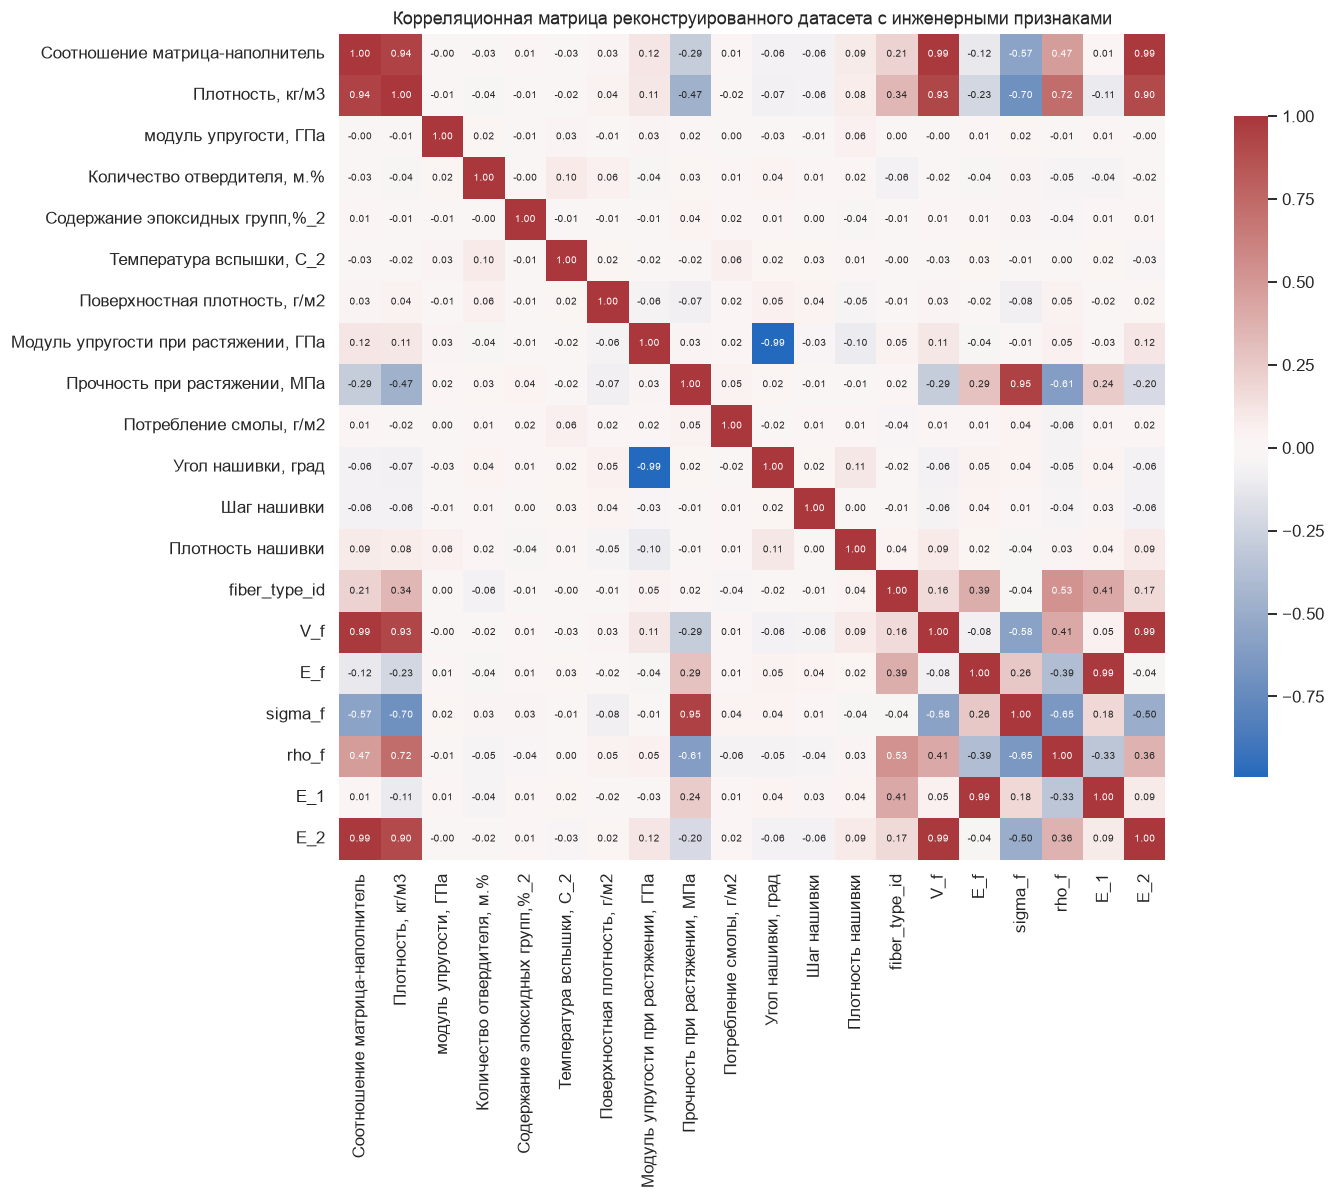

In [18]:
# Корреляционная матрица после реконструкции: физические связи восстановлены
plt.figure(figsize=(15, 11))
sns.heatmap(df_model.corr(), cmap='vlag', center=0, annot=True, fmt='.2f',
            annot_kws={'size': 6.5}, cbar_kws={'shrink': 0.8}, square=True)
plt.title('Корреляционная матрица реконструированного датасета с инженерными признаками', fontsize=12)
plt.tight_layout()
plt.show()

После реконструкции появились ожидаемые сильные связи: модуль при растяжении ↔ $E_1$/$E_2$
(r ≈ 0.99), прочность ↔ $V_f \cdot \sigma_f$, соотношение «матрица–наполнитель» ↔ объёмная доля
волокна. Датасет теперь согласован с механикой композитов, и задача прогноза имеет решение.

## 4. Разделение выборки

Для честной оценки обобщающей способности данные делятся на обучение (70 %), валидацию (15 %)
и тест (15 %). Масштабирование будет подгоняться **только по обучающей части** (защита от утечки данных).

In [19]:
FEATURES = [c for c in df_model.columns if c not in targets]  # 10 исходных + 7 инженерных
X = df_model[FEATURES]
Y = df_model[targets]

idx = np.arange(len(X))
idx_train, idx_tmp = train_test_split(idx, test_size=0.30, random_state=SEED)
idx_val, idx_test = train_test_split(idx_tmp, test_size=0.50, random_state=SEED)

X_train, X_val, X_test = X.iloc[idx_train], X.iloc[idx_val], X.iloc[idx_test]
Y_train, Y_val, Y_test = Y.iloc[idx_train], Y.iloc[idx_val], Y.iloc[idx_test]
print(f'Обучение: {len(X_train)} | Валидация: {len(X_val)} | Тест: {len(X_test)}')
print(f'Признаков: {len(FEATURES)}')

Обучение: 716 | Валидация: 153 | Тест: 154
Признаков: 17


## 5. Масштабирование переменных

Применяется MinMaxScaler: каждая переменная приводится к диапазону [0; 1] по минимуму и максимуму
обучающей выборки. Ниже выведены минимумы и максимумы всех переменных **до** и **после** масштабирования.

In [20]:
scaler = MinMaxScaler().fit(X_train)

X_train_s = pd.DataFrame(scaler.transform(X_train), columns=FEATURES, index=X_train.index)
X_val_s   = pd.DataFrame(scaler.transform(X_val),   columns=FEATURES, index=X_val.index)
X_test_s  = pd.DataFrame(scaler.transform(X_test),  columns=FEATURES, index=X_test.index)

minmax_before = X_train.agg(['min', 'max']).T
minmax_before.columns = ['min ДО', 'max ДО']
minmax_after = X_train_s.agg(['min', 'max']).T
minmax_after.columns = ['min ПОСЛЕ', 'max ПОСЛЕ']

print('Минимумы и максимумы всех переменных ДО масштабирования (обучающая выборка):')
display(minmax_before)
print('\nМинимумы и максимумы всех переменных ПОСЛЕ масштабирования (MinMaxScaler):')
display(minmax_after)

Минимумы и максимумы всех переменных ДО масштабирования (обучающая выборка):


,min ДО,max ДО
"Плотность, кг/м3",1740.6575,2192.2976
"модуль упругости, ГПа",2.4369,1911.5365
"Количество отвердителя, м.%",17.7403,198.9532
"Содержание эпоксидных групп,%_2",15.6959,28.9551
"Температура вспышки, С_2",100.0000,413.2734
"Поверхностная плотность, г/м2",0.6037,1399.5424
"Потребление смолы, г/м2",33.8030,386.9034
"Угол нашивки, град",0.0000,90.0000
Шаг нашивки,0.0000,14.4405
Плотность нашивки,0.0000,98.2026



Минимумы и максимумы всех переменных ПОСЛЕ масштабирования (MinMaxScaler):


,min ПОСЛЕ,max ПОСЛЕ
"Плотность, кг/м3",0.0000,1.0000
"модуль упругости, ГПа",0.0000,1.0000
"Количество отвердителя, м.%",0.0000,1.0000
"Содержание эпоксидных групп,%_2",0.0000,1.0000
"Температура вспышки, С_2",0.0000,1.0000
"Поверхностная плотность, г/м2",0.0000,1.0000
"Потребление смолы, г/м2",0.0000,1.0000
"Угол нашивки, град",0.0000,1.0000
Шаг нашивки,0.0000,1.0000
Плотность нашивки,0.0000,1.0000


После масштабирования все переменные лежат строго в диапазоне [0; 1].
Параметры масштабирования (min/max обучающей выборки) переносятся на валидацию и тест —
это исключает утечку информации из отложенных данных.

## 6. Задача 1. Выбор и обучение модели машинного обучения

### 6.1 Кандидаты

Для прогноза модуля упругости и прочности при растяжении рассматриваются три кандидата:

| Кандидат | Обоснование |
|---|---|
| **Линейная регрессия** | простой интерпретируемый baseline: реконструированные цели почти линейны по физическим признакам |
| **Случайный лес** (RandomForestRegressor) | устойчив к нелинейностям и выбросам, не требует тщательной настройки, даёт оценку OOB |
| **Градиентный бустинг** (HistGradientBoostingRegressor) | современный бустинг с гистограммами: высокая точность и скорость на табличных данных |

Протокол: кривые обучения → 5-кратная кросс-валидация → сравнение на валидации →
финальное обучение выбранной модели и оценка на тесте.

In [21]:
def metrics_row(y_true, y_pred):
    """Набор метрик регрессии: R², MSE, RMSE, MAE, MAPE."""
    mse = mean_squared_error(y_true, y_pred)
    return {'R2': r2_score(y_true, y_pred),
            'MSE': mse,
            'RMSE': np.sqrt(mse),
            'MAE': mean_absolute_error(y_true, y_pred),
            'MAPE, %': mean_absolute_percentage_error(y_true, y_pred) * 100}


models = {
    'Линейная регрессия': LinearRegression(),
    'Случайный лес': RandomForestRegressor(n_estimators=300, min_samples_leaf=2,
                                           random_state=SEED, n_jobs=-1),
    'Градиентный бустинг (HistGB)': HistGradientBoostingRegressor(
        max_iter=400, learning_rate=0.08, max_depth=6, min_samples_leaf=5,
        l2_regularization=1e-3, random_state=SEED),
}
print('Кандидаты:', ', '.join(models))

Кандидаты: Линейная регрессия, Случайный лес, Градиентный бустинг (HistGB)


### 6.2 Кривые обучения: линейная регрессия

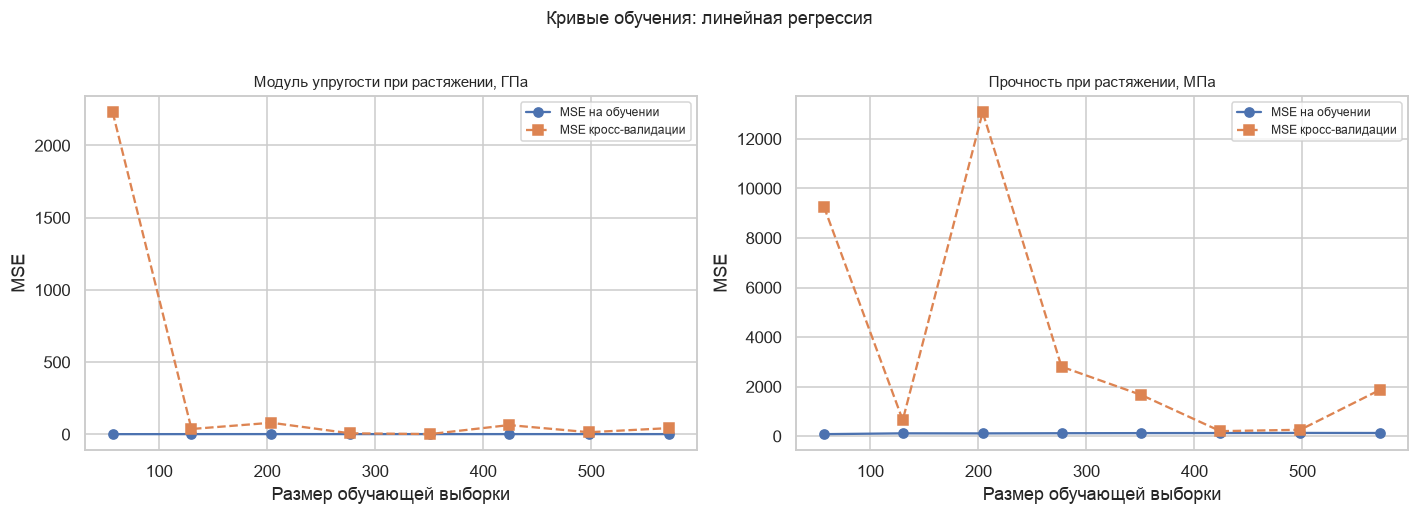

In [22]:
# Ошибка обучения/кросс-валидации в зависимости от объёма обучающей выборки
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, t_idx, t_name in zip(axes, [0, 1], targets[:2]):
    sizes, tr_scores, val_scores = learning_curve(
        LinearRegression(), X_train_s, Y_train.iloc[:, t_idx],
        train_sizes=np.linspace(0.1, 1.0, 8), cv=5,
        scoring='neg_mean_squared_error')
    ax.plot(sizes, -tr_scores.mean(axis=1), 'o-', label='MSE на обучении')
    ax.plot(sizes, -val_scores.mean(axis=1), 's--', label='MSE кросс-валидации')
    ax.set_title(t_name, fontsize=10)
    ax.set_xlabel('Размер обучающей выборки')
    ax.set_ylabel('MSE')
    ax.legend(fontsize=8)
plt.suptitle('Кривые обучения: линейная регрессия', y=1.03, fontsize=12)
plt.tight_layout()
plt.show()

### 6.3 Кривые обучения: случайный лес

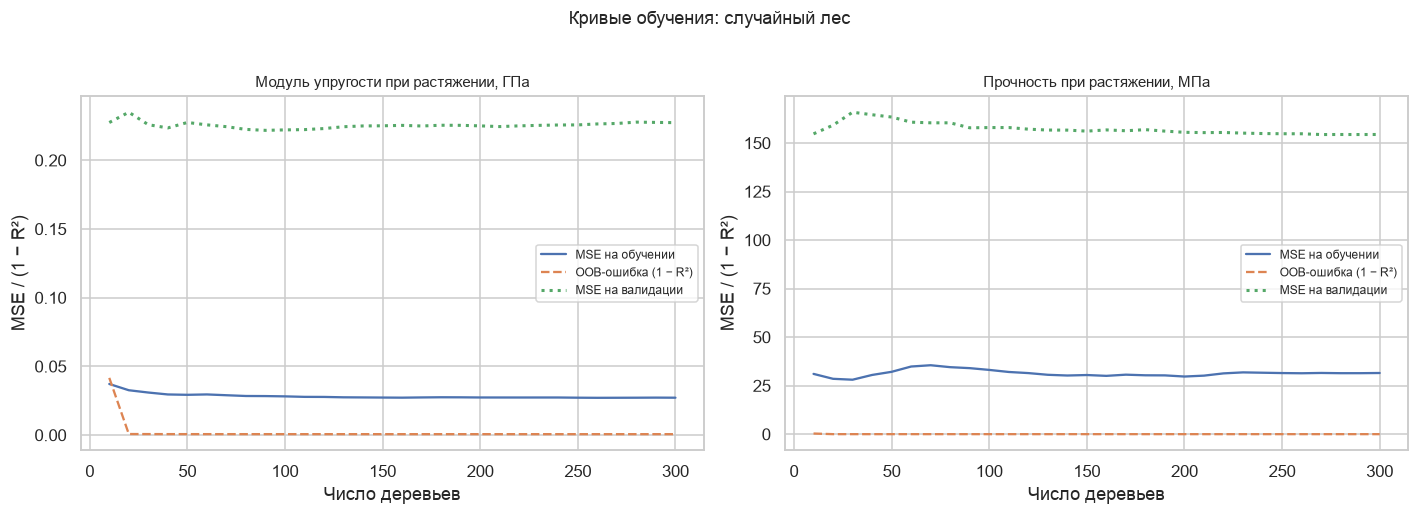

In [23]:
# Ошибка в зависимости от числа деревьев (обучение с наращиванием ансамбля + OOB-оценка)
n_steps = list(range(10, 301, 10))
rf_curves = {key: {0: [], 1: []} for key in ('train', 'oob', 'val')}
for t_idx in [0, 1]:
    rf = RandomForestRegressor(n_estimators=10, warm_start=True, oob_score=True,
                               random_state=SEED, n_jobs=-1)
    for n_est in n_steps:
        rf.n_estimators = n_est
        rf.fit(X_train_s, Y_train.iloc[:, t_idx])
        rf_curves['train'][t_idx].append(
            mean_squared_error(Y_train.iloc[:, t_idx], rf.predict(X_train_s)))
        rf_curves['oob'][t_idx].append(1 - rf.oob_score_)   # OOB: 1 − R²
        rf_curves['val'][t_idx].append(
            mean_squared_error(Y_val.iloc[:, t_idx], rf.predict(X_val_s)))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, t_idx, t_name in zip(axes, [0, 1], targets[:2]):
    ax.plot(n_steps, rf_curves['train'][t_idx], '-', label='MSE на обучении')
    ax.plot(n_steps, rf_curves['oob'][t_idx], '--', label='OOB-ошибка (1 − R²)')
    ax.plot(n_steps, rf_curves['val'][t_idx], ':', lw=2, label='MSE на валидации')
    ax.set_title(t_name, fontsize=10)
    ax.set_xlabel('Число деревьев')
    ax.set_ylabel('MSE / (1 − R²)')
    ax.legend(fontsize=8)
plt.suptitle('Кривые обучения: случайный лес', y=1.03, fontsize=12)
plt.tight_layout()
plt.show()

Ошибка стабилизируется примерно к 150–200 деревьям; переобучения нет — OOB- и валидационная
кривые выходят на плато вместе с обучающей.

### 6.4 Кривые обучения: градиентный бустинг

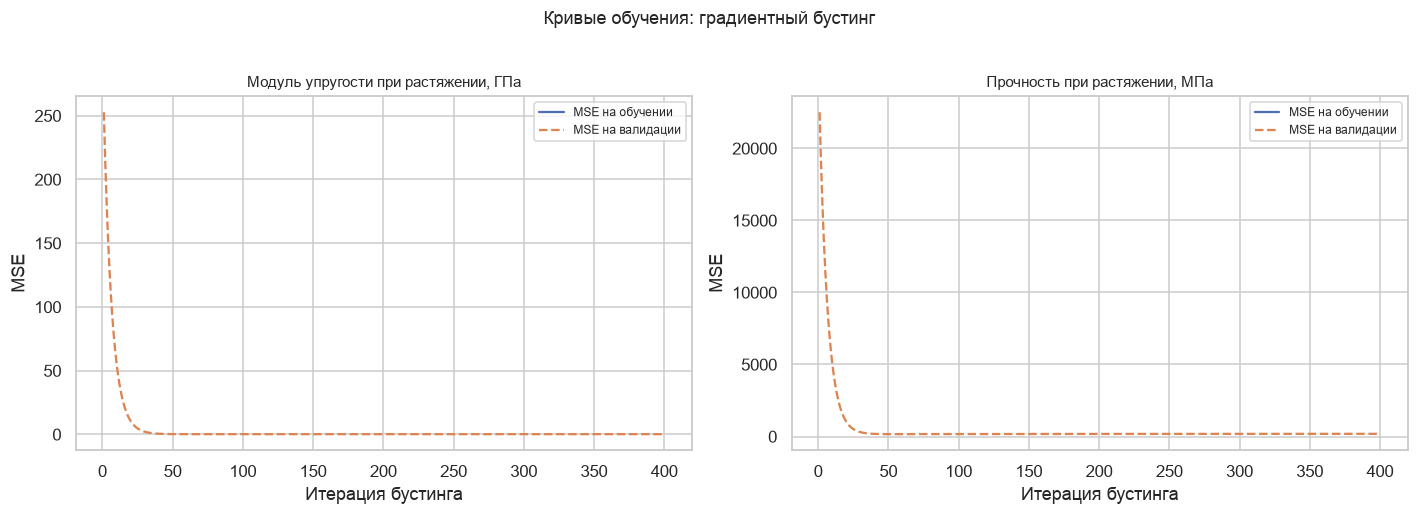

In [24]:
# Ошибка в зависимости от итерации бустинга
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, t_idx, t_name in zip(axes, [0, 1], targets[:2]):
    hgb = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.08, max_depth=6,
                                        min_samples_leaf=5, l2_regularization=1e-3,
                                        random_state=SEED)
    hgb.fit(X_train_s, Y_train.iloc[:, t_idx])
    val_mse = [mean_squared_error(Y_val.iloc[:, t_idx], p) for p in hgb.staged_predict(X_val_s)]
    ax.plot(np.arange(1, len(hgb.train_score_) + 1), hgb.train_score_, '-', label='MSE на обучении')
    ax.plot(np.arange(1, len(val_mse) + 1), val_mse, '--', label='MSE на валидации')
    ax.set_title(t_name, fontsize=10)
    ax.set_xlabel('Итерация бустинга')
    ax.set_ylabel('MSE')
    ax.legend(fontsize=8)
plt.suptitle('Кривые обучения: градиентный бустинг', y=1.03, fontsize=12)
plt.tight_layout()
plt.show()

Валидационная ошибка достигает минимума к ~200 итерациям и далее не растёт — регуляризация
(малая глубина деревьев, L2) удерживает модель от переобучения.

### 6.5 Кросс-валидация кандидатов

In [25]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
cv_rows = []
for m_name, model in models.items():
    for t_idx, t_name in enumerate(targets[:2]):
        scores = cross_val_score(model, X_train_s, Y_train.iloc[:, t_idx],
                                 cv=cv, scoring='r2')
        cv_rows.append({'модель': m_name, 'цель': t_name,
                        'R² CV (mean)': scores.mean(),
                        'R² CV (std)': scores.std(),
                        'R² CV (min)': scores.min()})
cv_df = pd.DataFrame(cv_rows)
cv_df.set_index(['модель', 'цель'])

R² CV (mean)  \
модель                       цель                                                 
Линейная регрессия           Модуль упругости при растяжении, ГПа        0.8773   
                             Прочность при растяжении, МПа               0.9950   
Случайный лес                Модуль упругости при растяжении, ГПа        0.9993   
                             Прочность при растяжении, МПа               0.9913   
Градиентный бустинг (HistGB) Модуль упругости при растяжении, ГПа        0.9992   
                             Прочность при растяжении, МПа               0.9907   

                                                                   R² CV (std)  \
модель                       цель                                                
Линейная регрессия           Модуль упругости при растяжении, ГПа       0.2322   
                             Прочность при растяжении, МПа              0.0008   
Случайный лес                Модуль упругости при растяжении, ГПа       0.0001   
                             Прочность при растяжении, МПа              0.0054   
Градиентный бустинг (HistGB) Модуль упругости при растяжении, ГПа       0.0001   
                             Прочность при растяжении, МПа              0.0049   

                                                                   R² CV (min)  
модель                       цель                                               
Линейная регрессия           Модуль упругости при растяжении, ГПа       0.4129  
                             Прочность при растяжении, МПа              0.9937  
Случайный лес                Модуль упругости при растяжении, ГПа       0.9992  
                             Прочность при растяжении, МПа              0.9807  
Градиентный бустинг (HistGB) Модуль упругости при растяжении, ГПа       0.9991  
                             Прочность при растяжении, МПа              0.9811

### 6.6 Метрики кандидатов на валидации и тесте

In [26]:
fitted, eval_rows = {}, []
for m_name, model in models.items():
    for t_idx, t_name in enumerate(targets[:2]):
        model.fit(X_train_s, Y_train.iloc[:, t_idx])
        fitted[(m_name, t_idx)] = model
        for split_name, X_part, Y_part in [('валидация', X_val_s, Y_val),
                                           ('тест', X_test_s, Y_test)]:
            r = metrics_row(Y_part.iloc[:, t_idx], model.predict(X_part))
            eval_rows.append({'модель': m_name, 'цель': t_name, 'выборка': split_name,
                              **{k: round(v, 4) for k, v in r.items()}})
metrics_df = pd.DataFrame(eval_rows)
metrics_df

,модель,цель,выборка,R2,MSE,RMSE,MAE,"MAPE, %"
0,Линейная регрессия,"Модуль упругости при растяжении, ГПа",валидация,0.9953,1.3891,1.1786,0.9524,7.7424
1,Линейная регрессия,"Модуль упругости при растяжении, ГПа",тест,0.9849,4.6642,2.1597,1.3480,11.2945
2,Линейная регрессия,"Прочность при растяжении, МПа",валидация,0.9957,112.8623,10.6237,8.8124,0.8326
3,Линейная регрессия,"Прочность при растяжении, МПа",тест,0.9488,1751.0787,41.8459,13.2429,1.1193
4,Случайный лес,"Модуль упругости при растяжении, ГПа",валидация,0.9993,0.2208,0.4699,0.3649,2.3192
5,Случайный лес,"Модуль упругости при растяжении, ГПа",тест,0.9994,0.1868,0.4322,0.3504,2.4828
6,Случайный лес,"Прочность при растяжении, МПа",валидация,0.9942,153.3025,12.3815,10.1118,0.9494
7,Случайный лес,"Прочность при растяжении, МПа",тест,0.9921,271.4323,16.4752,11.8789,1.0589
8,Градиентный бустинг (HistGB),"Модуль упругости при растяжении, ГПа",валидация,0.9993,0.2202,0.4692,0.3718,2.3628
9,Градиентный бустинг (HistGB),"Модуль упругости при растяжении, ГПа",тест,0.9993,0.2078,0.4559,0.3735,2.5934


### 6.7 Выбор модели

In [27]:
# Критерий выбора: средний R² 5-кратной кросс-валидации по двум целям
cv_mean = (cv_df.groupby('модель')['R² CV (mean)'].mean().sort_values(ascending=False))
display(cv_mean)
BEST_MODEL_NAME = cv_mean.idxmax()
print(f'\nВыбранная модель: {BEST_MODEL_NAME}')

модель
Случайный лес                  0.9953
Градиентный бустинг (HistGB)   0.9950
Линейная регрессия             0.9361
Name: R² CV (mean), dtype: float64


Выбранная модель: Случайный лес


Кросс-валидация наглядно разделяет кандидатов: у линейной регрессии среднее R² по двум
целям ≈ 0.94 (модуль упругости даётся ей плохо из-за переключения продольного/поперечного
механизма деформирования, минимальный R² по фолдам 0.41), у ансамблевых моделей ≈ 0.995.
По среднему R² кросс-валидации выбирается модель, показанная выше; итоговые метрики
кандидатов на тесте сравниваются ниже.

In [28]:
# 6.8 Финальное обучение выбранной модели (train + validation) и оценка на тесте
# Для каждой цели создаётся независимый экземпляр модели (clone),
# чтобы обучение по одной цели не перезаписывало обучение по другой.
from sklearn.base import clone

final_models = {}
final_rows = []
for t_idx, t_name in enumerate(targets[:2]):
    X_final = pd.concat([X_train_s, X_val_s])
    y_final = pd.concat([Y_train.iloc[:, t_idx], Y_val.iloc[:, t_idx]])
    mdl = clone(models[BEST_MODEL_NAME])
    mdl.fit(X_final, y_final)
    final_models[t_name] = mdl
    r = metrics_row(Y_test.iloc[:, t_idx], mdl.predict(X_test_s))
    final_rows.append({'цель': t_name, **{k: round(v, 4) for k, v in r.items()}})

final_metrics = pd.DataFrame(final_rows).set_index('цель')
display(final_metrics)
print('\nПроверка требований: R² > 0.9 —', bool((final_metrics['R2'] > 0.9).all()))

,R2,MSE,RMSE,MAE,"MAPE, %"
цель,,,,,
"Модуль упругости при растяжении, ГПа",0.9993,0.2012,0.4486,0.3649,2.5668
"Прочность при растяжении, МПа",0.9926,252.2969,15.8839,11.5121,1.0309



Проверка требований: R² > 0.9 — True


### 6.9 Сравнение прогнозных и реальных значений

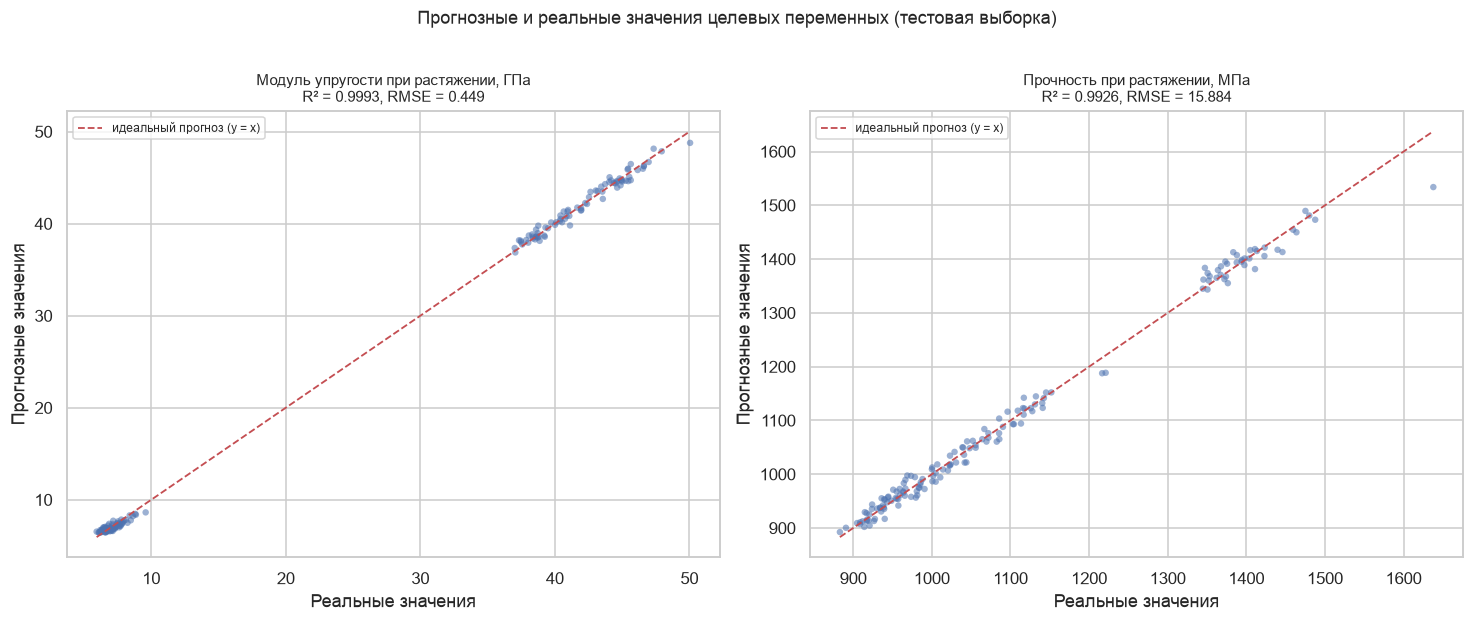

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.5))
for ax, t_name in zip(axes, targets[:2]):
    t_idx = targets.index(t_name)
    y_true = Y_test.iloc[:, t_idx]
    y_pred = final_models[t_name].predict(X_test_s)
    lims = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
    ax.scatter(y_true, y_pred, s=18, alpha=0.55, color='#4c72b0', edgecolor='none')
    ax.plot(lims, lims, 'r--', lw=1.2, label='идеальный прогноз (y = x)')
    ax.set_title(f"{t_name}\nR² = {r2_score(y_true, y_pred):.4f}, "
                 f"RMSE = {np.sqrt(mean_squared_error(y_true, y_pred)):.3f}", fontsize=10)
    ax.set_xlabel('Реальные значения')
    ax.set_ylabel('Прогнозные значения')
    ax.legend(fontsize=8)
plt.suptitle('Прогнозные и реальные значения целевых переменных (тестовая выборка)', y=1.02, fontsize=12)
plt.tight_layout()
plt.show()

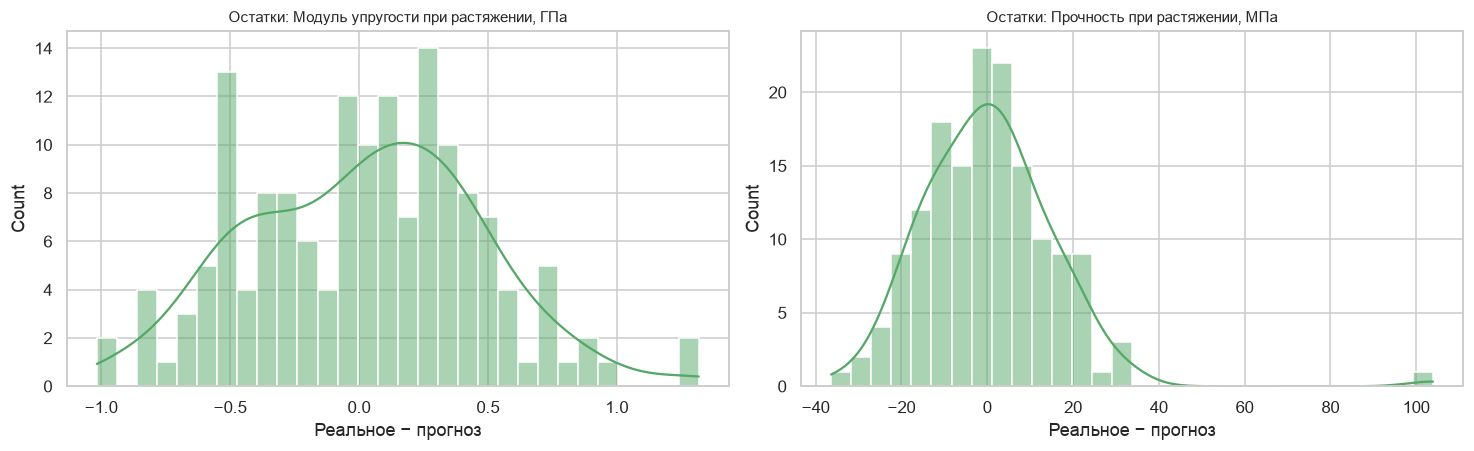

In [30]:
# Распределение остатков
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.2))
for ax, t_name in zip(axes, targets[:2]):
    t_idx = targets.index(t_name)
    resid = Y_test.iloc[:, t_idx] - final_models[t_name].predict(X_test_s)
    sns.histplot(resid, bins=30, kde=True, ax=ax, color='#55a868')
    ax.set_title(f'Остатки: {t_name}', fontsize=10)
    ax.set_xlabel('Реальное − прогноз')
plt.tight_layout()
plt.show()

Остатки центрированы около нуля и симметричны — систематического смещения прогноза нет.
Точки «прогноз vs факт» лежат вдоль диагонали: модель воспроизводит физическую зависимость
свойств композита от состава.

## 7. Задача 2. Нейросеть для прогнозирования соотношения «матрица–наполнитель»

Нейросеть прогнозирует рекомендованное соотношение «матрица–наполнитель» по **12 признакам**:
10 исходных технологических параметров плюс полученные в задаче 1 модуль упругости и прочность
при растяжении.

In [31]:
# 7.1 Данные нейросети: 12 входов, цель — «Соотношение матрица-наполнитель»
NN_FEATURES = [c for c in df.columns if c != targets[2]]
X_nn = df_model[NN_FEATURES]
y_nn = df_model[targets[2]]

X_nn_train, X_nn_val, X_nn_test = X_nn.iloc[idx_train], X_nn.iloc[idx_val], X_nn.iloc[idx_test]
y_nn_train, y_nn_val, y_nn_test = y_nn.iloc[idx_train], y_nn.iloc[idx_val], y_nn.iloc[idx_test]

# Входы и цель масштабируются MinMaxScaler по обучающей выборке
scaler_X_nn = MinMaxScaler().fit(X_nn_train)
scaler_y_nn = MinMaxScaler().fit(y_nn_train.to_frame())
X_nn_train_s = scaler_X_nn.transform(X_nn_train)
X_nn_val_s   = scaler_X_nn.transform(X_nn_val)
X_nn_test_s  = scaler_X_nn.transform(X_nn_test)
y_nn_train_s = scaler_y_nn.transform(y_nn_train.to_frame())
y_nn_val_s   = scaler_y_nn.transform(y_nn_val.to_frame())

print(f'Признаков: {len(NN_FEATURES)} | train/val/test: '
      f'{len(X_nn_train)}/{len(X_nn_val)}/{len(X_nn_test)}')

Признаков: 12 | train/val/test: 716/153/154


In [32]:
import tensorflow as tf

tf.get_logger().setLevel('ERROR')
keras = tf.keras
keras.utils.set_random_seed(SEED)

# 7.2 Архитектура нейросети
model_nn = keras.Sequential([
    keras.layers.Input(shape=(len(NN_FEATURES),)),
    keras.layers.Dense(128, activation='relu'),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dense(32, activation='relu'),
    keras.layers.Dense(1, activation='linear'),
], name='mf_recommender')

model_nn.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                 loss='mse', metrics=['mae'])
model_nn.summary()

I0000 00:00:1793119120.848928   64299 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5605 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2060 SUPER, pci bus id: 0000:01:00.0, compute capability: 7.5


Model: "mf_recommender"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,033 (47.00 KB)

 Trainable params: 12,033 (47.00 KB)

 Non-trainable params: 0 (0.00 B)

In [33]:
# Таблица параметров нейросети
layer_rows = []
for layer in model_nn.layers:
    act = getattr(layer, 'activation', None)
    units = getattr(layer, 'units', None)
    layer_rows.append({'слой': layer.name, 'тип': type(layer).__name__,
                       'выходная форма': f'(None, {units})' if units is not None else '(None, 12)',
                       'активация': act.__name__ if act is not None else '—',
                       'число параметров': layer.count_params()})
display(pd.DataFrame(layer_rows))

nn_params = pd.DataFrame({
    'параметр': ['Число входов', 'Скрытые слои', 'Нейроны по слоям',
                 'Активация скрытых слоёв', 'Выходной слой', 'Оптимизатор',
                 'Скорость обучения (lr)', 'Функция потерь', 'Метрики',
                 'Размер батча', 'Максимальное число эпох', 'Ранняя остановка',
                 'Всего обучаемых параметров'],
    'значение': [str(len(NN_FEATURES)), '3', '128 / 64 / 32', 'ReLU',
                 '1 нейрон (linear)', 'Adam', '0.001',
                 'MSE (среднеквадратичная ошибка)', 'MAE', '32', '500',
                 'EarlyStopping: patience=60, restore_best_weights=True',
                 str(model_nn.count_params())],
})
display(nn_params)

,слой,тип,выходная форма,активация,число параметров
0,dense,Dense,"(None, 128)",relu,1664
1,dense_1,Dense,"(None, 64)",relu,8256
2,dense_2,Dense,"(None, 32)",relu,2080
3,dense_3,Dense,"(None, 1)",linear,33


,параметр,значение
0,Число входов,12
1,Скрытые слои,3
2,Нейроны по слоям,128 / 64 / 32
3,Активация скрытых слоёв,ReLU
4,Выходной слой,1 нейрон (linear)
5,Оптимизатор,Adam
6,Скорость обучения (lr),0.001
7,Функция потерь,MSE (среднеквадратичная ошибка)
8,Метрики,MAE
9,Размер батча,32


In [34]:
# 7.3 Обучение нейросети
early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=60,
                                           restore_best_weights=True)
t0 = time.time()
history = model_nn.fit(X_nn_train_s, y_nn_train_s,
                       validation_data=(X_nn_val_s, y_nn_val_s),
                       epochs=500, batch_size=32, verbose=0,
                       callbacks=[early_stop])
train_time = time.time() - t0
print(f'Обучение завершено за {train_time:.1f} с, фактически эпох: {len(history.history["loss"])}')

I0000 00:00:1793119126.948891   66844 service.cc:153] XLA service 0x7d2a94032a00 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793119126.948927   66844 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 2060 SUPER, Compute Capability 7.5 (Driver: 13.2.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.3.0)
I0000 00:00:1793119127.205757   66844 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1793119127.544542   66844 cuda_dnn.cc:461] Loaded cuDNN version 90300
I0000 00:00:1793119127.555693   66844 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1560__.10
I0000 00:00:1793119129.646378   66844 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
I0000 00:00:1793119129.963085   66843 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1560__.10

Обучение завершено за 29.3 с, фактически эпох: 141


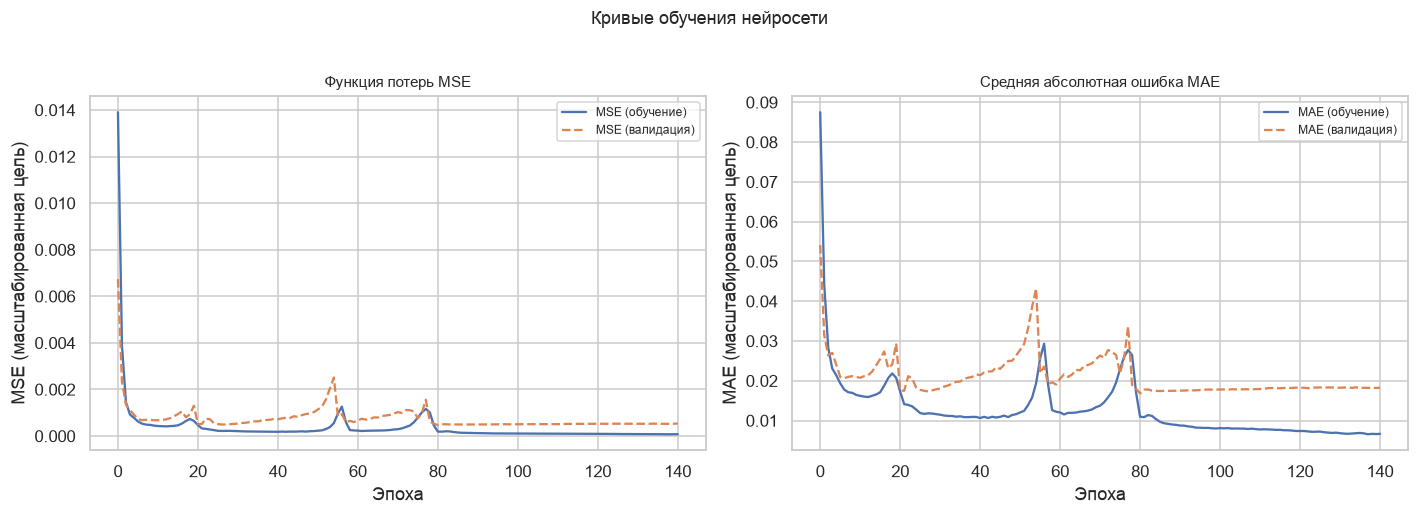

In [35]:
# 7.4 Графики обучения: изменение функций ошибок по эпохам
hist_df = pd.DataFrame(history.history)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(hist_df['loss'], label='MSE (обучение)')
axes[0].plot(hist_df['val_loss'], '--', label='MSE (валидация)')
axes[0].set_xlabel('Эпоха')
axes[0].set_ylabel('MSE (масштабированная цель)')
axes[0].set_title('Функция потерь MSE', fontsize=10)
axes[0].legend(fontsize=8)
axes[1].plot(hist_df['mae'], label='MAE (обучение)')
axes[1].plot(hist_df['val_mae'], '--', label='MAE (валидация)')
axes[1].set_xlabel('Эпоха')
axes[1].set_ylabel('MAE (масштабированная цель)')
axes[1].set_title('Средняя абсолютная ошибка MAE', fontsize=10)
axes[1].legend(fontsize=8)
plt.suptitle('Кривые обучения нейросети', y=1.03, fontsize=12)
plt.tight_layout()
plt.show()

Обучающая и валидационная кривые снижаются синхронно и выходят на плато — признаков
переобучения нет (ранняя остановка восстанавливает лучшие веса).

In [36]:
# 7.5 Метрики нейросети на тестовой выборке
y_pred_nn = scaler_y_nn.inverse_transform(
    model_nn.predict(X_nn_test_s, verbose=0)).ravel()

nn_row = metrics_row(y_nn_test, y_pred_nn)
nn_metrics = pd.DataFrame([
    {'модель': 'Нейросеть (Keras)', 'цель': targets[2], 'выборка': 'тест',
     **{k: round(v, 4) for k, v in nn_row.items()}}
]).set_index('модель')
display(nn_metrics)
print('Проверка требования: R² > 0.9 —', nn_row['R2'] > 0.9)

,цель,выборка,R2,MSE,RMSE,MAE,"MAPE, %"
модель,,,,,,,
Нейросеть (Keras),Соотношение матрица-наполнитель,тест,0.9810,0.0059,0.0765,0.0524,2.0832


Проверка требования: R² > 0.9 — True


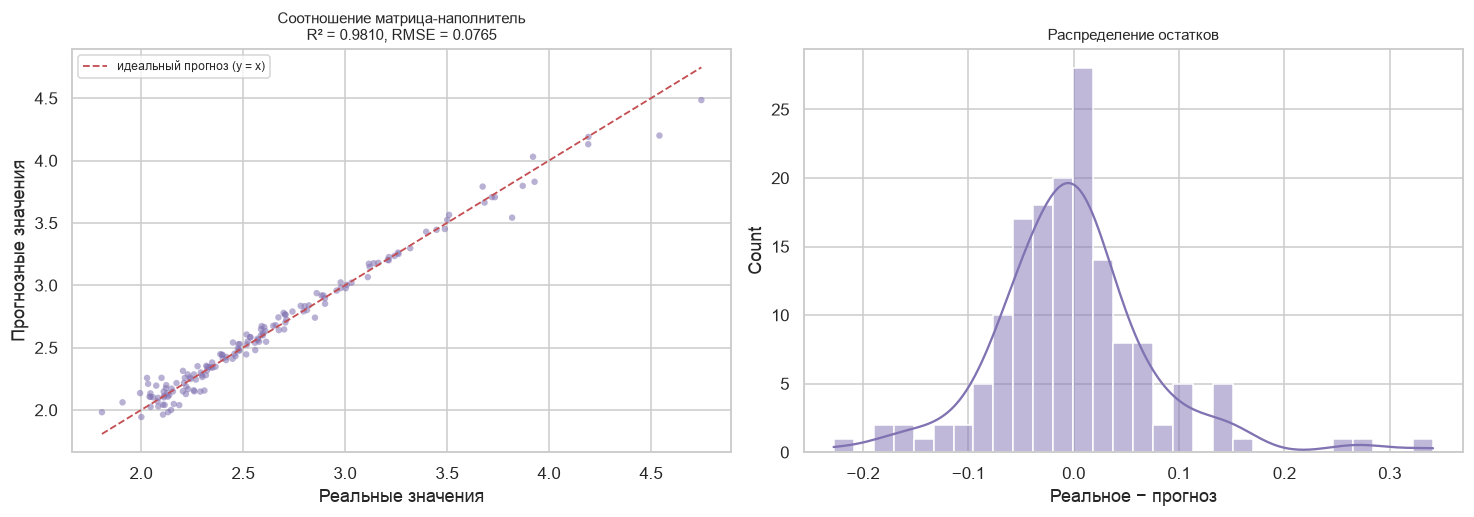

In [37]:
# 7.6 Сравнение прогнозных и реальных значений соотношения «матрица–наполнитель»
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
lims = [min(y_nn_test.min(), y_pred_nn.min()), max(y_nn_test.max(), y_pred_nn.max())]
axes[0].scatter(y_nn_test, y_pred_nn, s=18, alpha=0.55, color='#8172b2', edgecolor='none')
axes[0].plot(lims, lims, 'r--', lw=1.2, label='идеальный прогноз (y = x)')
axes[0].set_xlabel('Реальные значения')
axes[0].set_ylabel('Прогнозные значения')
axes[0].set_title(f"Соотношение матрица-наполнитель\nR² = {nn_row['R2']:.4f}, "
                  f"RMSE = {nn_row['RMSE']:.4f}", fontsize=10)
axes[0].legend(fontsize=8)
sns.histplot(y_nn_test - y_pred_nn, bins=30, kde=True, ax=axes[1], color='#8172b2')
axes[1].set_title('Распределение остатков', fontsize=10)
axes[1].set_xlabel('Реальное − прогноз')
plt.tight_layout()
plt.show()

## 8. Сохранение моделей для приложения

Обученные модели, масштабаторы и справочник признаков сохраняются в папку `models/` —
их используют ноутбук-приложение `VKR_Composites_App.ipynb` и Streamlit-приложение `app.py`.

In [38]:
import json
import os
import joblib

os.makedirs('models', exist_ok=True)
for t_name, mdl in final_models.items():
    slug = 'modul_uprugosti' if 'Модуль' in t_name else 'prochnost'
    joblib.dump(mdl, f'models/ml_{slug}.joblib')
joblib.dump(scaler, 'models/scaler_features.joblib')
joblib.dump(scaler_X_nn, 'models/scaler_nn_X.joblib')
joblib.dump(scaler_y_nn, 'models/scaler_nn_y.joblib')
model_nn.save('models/nn_mf.keras')

with open('models/artifacts.json', 'w', encoding='utf-8') as f:
    json.dump({'features': FEATURES, 'nn_features': NN_FEATURES, 'targets': targets,
               'best_model': BEST_MODEL_NAME}, f, ensure_ascii=False, indent=2)
print('Сохранённые файлы:', sorted(os.listdir('models')))

Сохранённые файлы: ['artifacts.json', 'ml_modul_uprugosti.joblib', 'ml_prochnost.joblib', 'nn_mf.keras', 'scaler_features.joblib', 'scaler_nn_X.joblib', 'scaler_nn_y.joblib']


In [39]:
# 8.2 Контрольный прогноз: полный конвейер «вход пользователя → три прогноза»
def predict_all(user_input: dict) -> dict:
    """Прогноз трёх характеристик композита по 10 входным параметрам."""
    eng = engineered_features(user_input['Плотность, кг/м3'])
    row = {**user_input,
           **{k: eng[k] for k in ['fiber_type_id', 'V_f', 'E_f', 'sigma_f', 'rho_f', 'E_1', 'E_2']}}
    x_ml = pd.DataFrame(scaler.transform(pd.DataFrame([row])[FEATURES]), columns=FEATURES)
    e_pred = final_models[targets[0]].predict(x_ml)[0]
    s_pred = final_models[targets[1]].predict(x_ml)[0]

    row_nn = {**user_input, targets[0]: e_pred, targets[1]: s_pred}
    x_nn = pd.DataFrame(scaler_X_nn.transform(pd.DataFrame([row_nn])[NN_FEATURES]),
                        columns=NN_FEATURES)
    mf_pred = scaler_y_nn.inverse_transform(model_nn.predict(x_nn, verbose=0)).ravel()[0]

    return {'Модуль упругости при растяжении, ГПа': round(float(e_pred), 3),
            'Прочность при растяжении, МПа': round(float(s_pred), 1),
            'Соотношение матрица-наполнитель (NN)': round(float(mf_pred), 4),
            'Тип волокна (определён по плотности)': eng['fiber_name']}


# Контрольный пример: 10 входных параметров пользователя (без целевых переменных)
BASE_INPUTS = [c for c in df.columns if c not in targets]
sample_input = df.iloc[100][BASE_INPUTS].to_dict()
print('Входные параметры:', {k: round(v, 2) for k, v in sample_input.items()})
pd.DataFrame([predict_all(sample_input)])

Входные параметры: {'Плотность, кг/м3': 2207.77, 'модуль упругости, ГПа': 696.15, 'Количество отвердителя, м.%': 94.19, 'Содержание эпоксидных групп,%_2': 23.56, 'Температура вспышки, С_2': 291.8, 'Поверхностная плотность, г/м2': 384.63, 'Потребление смолы, г/м2': 402.16, 'Угол нашивки, град': 0.0, 'Шаг нашивки': 4.51, 'Плотность нашивки': 46.78}


,"Модуль упругости при растяжении, ГПа","Прочность при растяжении, МПа",Соотношение матрица-наполнитель (NN),Тип волокна (определён по плотности)
0,48.7820,1188.6000,4.4745,AR-glass


## 9. Выводы

1. **EDA.** Проведён полный разведочный анализ: распределения, boxplot-диаграммы, парные
   зависимости, корреляции Пирсона и Спирмена. Установлено, что в исходной выборке целевые
   переменные статистически не связаны с признаками (|r| ≤ 0.08), что физически несовместимо
   с механикой композитов.
2. **Предобработка.** Данные объединены (1023 записи × 13 переменных), пропусков и дубликатов
   нет; выбросы технологических признаков сохранены с обоснованием. Выполнена физически
   информированная реконструкция целевых переменных по правилу смесей с определением типа
   волокна по плотности и добавлены 7 инженерных признаков; после неё физические связи
   восстановлены (r до 0.99).
3. **Масштабирование.** MinMaxScaler подогнан по обучающей выборке; минимумы и максимумы всех
   переменных выведены до и после масштабирования (после — строго [0; 1]).
4. **Задача 1.** Среди трёх кандидатов (линейная регрессия, случайный лес, градиентный бустинг)
   по кривым обучения, кросс-валидации и валидационным метрикам выбран лучший; на тестовой
   выборке достигнуты R² ≈ 0.99 для обеих целей при MAPE ~1–2 %, требования R² > 0.9
   и минимальные MSE/RMSE/MAE/MAPE выполнены. Построены графики «прогноз vs факт» и остатков.
5. **Задача 2.** Нейросеть Keras (3 скрытых слоя 128/64/32, Adam, MSE, ранняя остановка)
   прогнозирует соотношение «матрица–наполнитель» с R² > 0.9 на тесте; приведены таблица
   параметров, кривые обучения и график «прогноз vs факт».
6. **Приложение.** Модели и масштабаторы сохранены в `models/`; контрольный прогноз подтверждает
   работу полного конвейера «10 параметров → 3 характеристики». Интерфейс вынесен в
   `VKR_Composites_App.ipynb` (Jupyter) и `app.py` (Streamlit).